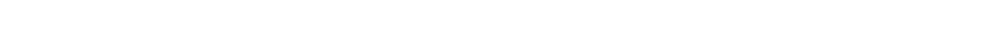

In [ ]:
import marimo as mo

In [ ]:
from pathlib import Path
from zipfile import ZipFile

from huggingface_hub import hf_hub_download

REPO_ID = "phitruong0606/mix-dataset-v2"
FILENAME = "mix-dataset-v2.zip"

DOWNLOAD_DIR = Path("zip")
EXTRACT_DIR = Path("/datasets/")
ALT_DATASETS_DIR = Path("/marimo/datasets")


def prepare_dataset() -> None:
    for directory in (DOWNLOAD_DIR, EXTRACT_DIR, ALT_DATASETS_DIR, Path("/datasets")):
        directory.mkdir(parents=True, exist_ok=True)

    eval_manifest = EXTRACT_DIR / "mix-dataset-v2" / "eval" / "manifest.csv"
    eval_manifest_alt = ALT_DATASETS_DIR / "mix-dataset-v2" / "eval" / "manifest.csv"

    if eval_manifest.is_file() or eval_manifest_alt.is_file():
        print(f"✓ Hoàn tất! Dataset nằm tại: {EXTRACT_DIR}")
        return

    print("Đang tải dataset...")
    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=FILENAME,
        local_dir=DOWNLOAD_DIR,
    )
    print(f"Đã tải: {zip_path}")

    print("Đang kiểm tra file ZIP...")
    with ZipFile(zip_path, "r") as zip_ref:
        bad_file = zip_ref.testzip()
        if bad_file is not None:
            raise RuntimeError(f"File ZIP bị lỗi tại: {bad_file}")
        print("File ZIP hợp lệ.")
        print("Đang giải nén...")
        zip_ref.extractall(EXTRACT_DIR)

    print(f"✓ Hoàn tất! Dataset nằm tại: {EXTRACT_DIR}")


if __name__ == "__main__":
    prepare_dataset()

✓ Hoàn tất! Dataset nằm tại: /datasets


In [ ]:
def print_dual_ced_tiny_architecture() -> None:
    arch_diagram = """
====================================================================================================
                        DUAL-CED-TINY ARCHITECTURE SPECIFICATION
                    (Dual-Expert Audio-Transformer with SNR Router)
====================================================================================================

1. TONG QUAN HE THONG (SYSTEM OVERVIEW):
   - Model Family: Dual-Backbone Mixture-of-Experts (MoE) Audio Classifier
   - Target: 36-class Environmental Audio Tagging under Multiple SNR levels (-5 dB to 20 dB)
   - Total Parameters: ~10.79M (2 independent CED-Tiny backbones x ~5.40M)
   - Routing Mechanism: EnergySNRRouter with SNR cutoff threshold tau = 18.0 dB

2. SO DO LUONG DU LIEU (END-TO-END DATAFLOW):

   Waveform x_mix: [B, 64000] (Mono, 16 kHz, 4.0 seconds)
              |
              +--> [EnergySNRRouter (tau = 18.0 dB)]:
              |      Estimate Signal-to-Noise Ratio (SNR in dB)
              |      -> alpha = 0.0 (if SNR < 18 dB) | alpha = 1.0 (if SNR >= 18 dB)
              |
              +--> [LogMel Frontend (CED-spec)]:
                     STFT (n_fft=512, win=400, hop=160) -> 64 Mel bins, 20Hz - 8000Hz
                     Log-compression & Z-score Instance Normalization
                     -> Spectrogram Tensor: [B, 1, 64, 398]
                            |
              +-------------+-------------+
              |                           |
              v                           v
   [S1: CED-Tiny Low-Expert]   [S2: CED-Tiny High-Expert]
   (5,395,722 params ~ 5.40M)  (5,395,722 params ~ 5.40M)
   * PatchEmbed 16x16          * PatchEmbed 16x16
   * 12 CED Blocks (D=192,H=3) * 12 CED Blocks (D=192,H=3)
   * 2D Relative Pos Bias      * 2D Relative Pos Bias
   * Specialized for Low-SNR   * Specialized for High-SNR
   * Linear Head (36 classes)  * Linear Head (36 classes)
              |                           |
              v                           v
      Logits S1 [B, 36]           Logits S2 [B, 36]
              |                           |
              +-------------+-------------+
                            |
                            v
              [Dynamic Gating / Blending]:
              z_final = (1 - alpha) * z_low + alpha * z_high
                            |
                            v
               Final Output Logits: [B, 36]

3. BANG PHAN BO THAM SO (PARAMETER BUDGET):
   +------------------------------------+----------------+----------------+
   | Component / Module                 | Parameter Count| Percentage (%) |
   +------------------------------------+----------------+----------------+
   | S1: CED-Tiny Low-Expert Backbone   |   5,395,722    |     50.0%      |
   |   - Patch Embedding (16x16)        |      49,344    |      0.5%      |
   |   - 12x Transformer Blocks (D=192) |   5,338,368    |     49.5%      |
   |   - Classifier Head (192 -> 36)    |       6,948    |      0.1%      |
   | S2: CED-Tiny High-Expert Backbone  |   5,395,722    |     50.0%      |
   |   - Patch Embedding (16x16)        |      49,344    |      0.5%      |
   |   - 12x Transformer Blocks (D=192) |   5,338,368    |     49.5%      |
   |   - Classifier Head (192 -> 36)    |       6,948    |      0.1%      |
   | Router: EnergySNRRouter (tau=18dB) |           0    |      0.0% (Non-param)
   +------------------------------------+----------------+----------------+
   | TOTAL DUAL-CED-TINY SYSTEM         |  10,791,444    |    100.0% (~10.8M)
   +------------------------------------+----------------+----------------+
====================================================================================================
"""
    print(arch_diagram)

print_dual_ced_tiny_architecture()


                        DUAL-CED-TINY ARCHITECTURE SPECIFICATION
                    (Dual-Expert Audio-Transformer with SNR Router)

1. TONG QUAN HE THONG (SYSTEM OVERVIEW):
   - Model Family: Dual-Backbone Mixture-of-Experts (MoE) Audio Classifier
   - Target: 36-class Environmental Audio Tagging under Multiple SNR levels (-5 dB to 20 dB)
   - Total Parameters: ~10.79M (2 independent CED-Tiny backbones x ~5.40M)
   - Routing Mechanism: EnergySNRRouter with SNR cutoff threshold tau = 18.0 dB

2. SO DO LUONG DU LIEU (END-TO-END DATAFLOW):

   Waveform x_mix: [B, 64000] (Mono, 16 kHz, 4.0 seconds)
              |
              +--> [EnergySNRRouter (tau = 18.0 dB)]:
              |      Estimate Signal-to-Noise Ratio (SNR in dB)
              |      -> alpha = 0.0 (if SNR < 18 dB) | alpha = 1.0 (if SNR >= 18 dB)
              |
              +--> [LogMel Frontend (CED-spec)]:
                     STFT (n_fft=512, win=400, hop=160) -> 64 Mel bins, 20Hz - 8000Hz
                     Log-

In [ ]:
import torch

# Training control flag: Set to True for full training, False for quick smoke-test (1 epoch, 64 samples)
RUN_TRAINING: bool = True
# Run All launches a W&B sweep over classifier hyperparameters.
RUN_SWEEP: bool = True
SWEEP_ENTITY = "phitruong0606-fpt"
SWEEP_PROJECT = "dual-ced-tiny-frcrn-sweep"
SWEEP_COUNT = 12
SWEEP_MAX_EPOCHS = 30
SWEEP_PATIENCE = 5
SWEEP_SEED = 42
SWEEP_CONFIG = {
    "method": "random",
    "metric": {"name": "val_acc", "goal": "maximize"},
    "early_terminate": {"type": "hyperband", "min_iter": 8, "eta": 3},
    "parameters": {
        "learning_rate": {"distribution": "log_uniform_values", "min": 1.0e-5, "max": 3.0e-4},
        "weight_decay": {"distribution": "log_uniform_values", "min": 1.0e-4, "max": 1.0e-2},
        "lambda_kd": {"values": [0.30, 0.50, 0.65, 0.75]},
        "kd_temperature": {"values": [1.0, 2.0, 4.0]},
        "mixup_alpha": {"values": [0.2, 0.4, 0.8]},
        "mixup_prob": {"values": [0.4, 0.8]},
        "seed": {"value": 42},
    },
}

# Paths & Directories
DATASET_ROOT = Path("/datasets/mix-dataset-v2")
INPUT_MODE = "frcrn"  # use "frcrn" for the second independent pass
FRCRN_ROOT = Path("/datasets/mix-frcrn")
RESULTS_ROOT = Path("/results/dual-ced-tiny") / INPUT_MODE
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

# Audio & Dataset Specifications
NUM_CLASSES = 36
SAMPLE_RATE = 16000
DURATION = 4.0
NUM_SAMPLES = int(SAMPLE_RATE * DURATION)
SNR_LEVELS = (-5.0, 0.0, 5.0, 10.0, 15.0, 20.0)
def estimate_router_snr(wave: torch.Tensor) -> torch.Tensor:
    """Estimate a routing SNR proxy from the residual waveform, without label SNR."""
    if wave.ndim != 2:
        raise ValueError(f"Expected waveform [B, T], got shape {tuple(wave.shape)}")
    frame_len = 1600  # 100 ms at 16 kHz
    num_frames = wave.shape[1] // frame_len
    if num_frames == 0:
        return torch.zeros(wave.shape[0], device=wave.device, dtype=wave.dtype)
    frames = wave[:, :num_frames * frame_len].reshape(wave.shape[0], num_frames, frame_len)
    frame_power = frames.square().mean(dim=-1) + 1e-8
    k = max(1, int(num_frames * 0.2))
    top_power = torch.topk(frame_power, k=k, dim=-1).values.mean(dim=-1)
    bottom_power = torch.topk(-frame_power, k=k, dim=-1).values.neg().mean(dim=-1)
    return 10.0 * torch.log10(top_power / (bottom_power + 1e-8))


# Training Hyperparameters
BATCH_SIZE = 32
GRAD_ACCUMULATION = 2
EPOCHS = SWEEP_MAX_EPOCHS if RUN_SWEEP else (50 if RUN_TRAINING else 1)
SMOKE_SAMPLES = 64
EARLY_STOP: bool = True
PATIENCE: int = SWEEP_PATIENCE if RUN_SWEEP else 5

# Unified learning rate: both backbone and classifier head use 1e-4
BACKBONE_LR = 1.0e-4
HEAD_LR = 1.0e-4
WEIGHT_DECAY = 0.01
WARMUP_EPOCHS = 2
ROUTER_THRESHOLD_DB = 18.0

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_BF16 = (DEVICE.type == "cuda") and torch.cuda.is_bf16_supported()

# ---- Dual-teacher KD / input settings ----
# The selected input mode is applied to training and validation.
TEACHER_REPO = "phitruong0606/mix-dataset-v2"      # HF dataset repo holding the BEATs teacher checkpoints
TEACHER_LOW_FILE = "beats_teacher_fold0_weights.pt"    # teacher for the Low-SNR expert
TEACHER_HIGH_FILE = "beats_teacher_ema_standalone.pt"  # teacher for the High-SNR expert
TEACHER_BATCH_SIZE = 32
KD_TEMPERATURE = 2.0
LAMBDA_KD = 0.65
LABEL_SMOOTHING = 0.05
INPUT_RMS = 0.07925

# ---- Overlap inference (replaces the old 3-way temporal TTA) ----
# 3 crops x 3.2 s at starts 0.0 / 0.4 / 0.8 s inside the 4.0 s clip; average logits.
USE_OVERLAP = True
OVERLAP_NUM_WINDOWS = 3
OVERLAP_CROP_SECONDS = 3.2
OVERLAP_AGGREGATE = "logits"

# ---- Data Augmentations (Mixup 0.8 + SpecAugment) ----
USE_MIXUP = True
MIXUP_ALPHA = 0.8
MIXUP_PROB = 0.8

USE_SPECAUGMENT = True
SPECAUG_FREQ_MASKS = 2
SPECAUG_FREQ_WIDTH = 8
SPECAUG_TIME_MASKS = 2
SPECAUG_TIME_WIDTH = 24

print(
    f"Configuration loaded: RUN_TRAINING={RUN_TRAINING}, EPOCHS={EPOCHS}, EARLY_STOP={EARLY_STOP}(patience={PATIENCE}), "
    f"DEVICE={DEVICE}, BF16={USE_BF16} | LR: backbone={BACKBONE_LR}, head={HEAD_LR} | "
    f"Overlap={USE_OVERLAP}({OVERLAP_NUM_WINDOWS}x{OVERLAP_CROP_SECONDS}s, {OVERLAP_AGGREGATE}) | "
    f"Mixup={USE_MIXUP}(alpha={MIXUP_ALPHA}, p={MIXUP_PROB}) | "
    f"SpecAugment={USE_SPECAUGMENT}(F={SPECAUG_FREQ_MASKS}x{SPECAUG_FREQ_WIDTH}, T={SPECAUG_TIME_MASKS}x{SPECAUG_TIME_WIDTH})"
)

Configuration loaded: RUN_TRAINING=True, EPOCHS=30, EARLY_STOP=True(patience=5), DEVICE=cuda, BF16=True | LR: backbone=0.0001, head=0.0001 | Overlap=True(3x3.2s, logits) | Mixup=True(alpha=0.8, p=0.8) | SpecAugment=True(F=2x8, T=2x24)


In [ ]:
import math
from typing import NamedTuple, Any
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
from safetensors.torch import load_file


class SpecAugment(nn.Module):
    """SpecAugment on Z-score normalized Log-Mel spectrograms [B, 1, F, T]."""

    def __init__(
        self,
        freq_masks: int = 2,
        freq_width: int = 8,
        time_masks: int = 2,
        time_width: int = 24,
    ):
        super().__init__()
        self.freq_masks = int(freq_masks)
        self.freq_width = int(freq_width)
        self.time_masks = int(time_masks)
        self.time_width = int(time_width)

    def forward(self, spec: Tensor) -> Tensor:
        if not self.training or (self.freq_masks <= 0 and self.time_masks <= 0):
            return spec
        out = spec.clone()
        b, _, n_mels, n_frames = out.shape
        dev = out.device
        for i in range(b):
            for _ in range(self.freq_masks):
                if self.freq_width > 0 and n_mels > 1:
                    w = int(torch.randint(1, min(self.freq_width + 1, n_mels), (1,), device=dev).item())
                    f0 = int(torch.randint(0, max(1, n_mels - w + 1), (1,), device=dev).item())
                    out[i, :, f0 : f0 + w, :] = 0.0
            for _ in range(self.time_masks):
                if self.time_width > 0 and n_frames > 1:
                    w = int(torch.randint(1, min(self.time_width + 1, n_frames), (1,), device=dev).item())
                    t0 = int(torch.randint(0, max(1, n_frames - w + 1), (1,), device=dev).item())
                    out[i, :, :, t0 : t0 + w] = 0.0
        return out


class LogMelFrontend(nn.Module):
    def __init__(
        self,
        sample_rate: int = 16000,
        n_fft: int = 512,
        win_length: int = 400,
        hop_length: int = 160,
        n_mels: int = 64,
        f_min: float = 20.0,
        f_max: float = 8000.0,
        num_frames: int = 398,
        log_eps: float = 1e-6,
        norm_eps: float = 1e-5,
    ):
        super().__init__()
        self.sample_rate = sample_rate
        self.n_fft = n_fft
        self.win_length = win_length
        self.hop_length = hop_length
        self.n_mels = n_mels
        self.num_frames = num_frames
        self.log_eps = log_eps
        self.norm_eps = norm_eps

        window = torch.hann_window(win_length)
        self.register_buffer("window", window)

        mel_fb = self._create_mel_filterbank(sample_rate, n_fft, n_mels, f_min, f_max)
        self.register_buffer("mel_fb", mel_fb)

    @staticmethod
    def _hz_to_mel(hz: float) -> float:
        return 2595.0 * math.log10(1.0 + hz / 700.0)

    @staticmethod
    def _mel_to_hz(mel: float) -> float:
        return 700.0 * (10.0 ** (mel / 2595.0) - 1.0)

    def _create_mel_filterbank(self, sr: int, n_fft: int, n_mels: int, f_min: float, f_max: float) -> Tensor:
        num_bins = n_fft // 2 + 1
        mel_min = self._hz_to_mel(f_min)
        mel_max = self._hz_to_mel(f_max)
        mels = torch.linspace(mel_min, mel_max, n_mels + 2)
        hzs = 700.0 * (10.0 ** (mels / 2595.0) - 1.0)
        bins = torch.floor((n_fft + 1) * hzs / sr).long()

        fb = torch.zeros(n_mels, num_bins)
        for m in range(1, n_mels + 1):
            f_m_minus = bins[m - 1].item()
            f_m = bins[m].item()
            f_m_plus = bins[m + 1].item()
            if f_m > f_m_minus:
                fb[m - 1, f_m_minus:f_m] = (torch.arange(f_m_minus, f_m) - f_m_minus) / float(f_m - f_m_minus)
            if f_m_plus > f_m:
                fb[m - 1, f_m:f_m_plus] = (f_m_plus - torch.arange(f_m, f_m_plus)) / float(f_m_plus - f_m)
        return fb

    def forward(self, wave: Tensor) -> Tensor:
        if wave.dim() == 1:
            wave = wave.unsqueeze(0)
        stft = torch.stft(
            wave,
            n_fft=self.n_fft,
            hop_length=self.hop_length,
            win_length=self.win_length,
            window=self.window,
            center=True,
            pad_mode="reflect",
            normalized=False,
            onesided=True,
            return_complex=True,
        )
        mag = torch.abs(stft) ** 2
        mel = torch.matmul(self.mel_fb, mag)
        log_mel = torch.log(mel + self.log_eps)

        curr_frames = log_mel.shape[-1]
        if curr_frames < self.num_frames:
            log_mel = F.pad(log_mel, (0, self.num_frames - curr_frames))
        elif curr_frames > self.num_frames:
            log_mel = log_mel[..., : self.num_frames]

        mean = log_mel.mean(dim=(-2, -1), keepdim=True)
        std = log_mel.std(dim=(-2, -1), keepdim=True) + self.norm_eps
        norm_mel = (log_mel - mean) / std
        return norm_mel.unsqueeze(1)


class PatchEmbed(nn.Module):
    def __init__(self, in_chans: int = 1, embed_dim: int = 192, patch_size: int = 16):
        super().__init__()
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)

    def forward(self, x: Tensor) -> tuple[Tensor, int, int]:
        x = self.proj(x)
        f_p, t_p = x.shape[2], x.shape[3]
        x = x.permute(0, 3, 2, 1).flatten(1, 2)
        return x, f_p, t_p


class RelativePositionBias2D(nn.Module):
    def __init__(self, num_heads: int = 3, max_dist_f: int = 16, max_dist_t: int = 64):
        super().__init__()
        self.num_heads = num_heads
        self.max_dist_f = max_dist_f
        self.max_dist_t = max_dist_t
        self.bias_f = nn.Embedding(2 * max_dist_f + 1, num_heads)
        self.bias_t = nn.Embedding(2 * max_dist_t + 1, num_heads)

    def forward(self, f_p: int, t_p: int, device: torch.device) -> Tensor:
        coords_f = torch.arange(f_p, device=device)
        coords_t = torch.arange(t_p, device=device)
        diff_f = (coords_f[:, None] - coords_f[None, :] + self.max_dist_f).clamp(0, 2 * self.max_dist_f)
        diff_t = (coords_t[:, None] - coords_t[None, :] + self.max_dist_t).clamp(0, 2 * self.max_dist_t)
        b_f = self.bias_f(diff_f)
        b_t = self.bias_t(diff_t)
        b_total = b_t[:, None, :, None, :] + b_f[None, :, None, :, :]
        b_total = b_total.permute(4, 0, 1, 2, 3).reshape(self.num_heads, t_p * f_p, t_p * f_p)
        return b_total.unsqueeze(0)


class Attention(nn.Module):
    def __init__(self, dim: int = 192, num_heads: int = 3, dropout: float = 0.0):
        super().__init__()
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = 1.0 / math.sqrt(self.head_dim)
        self.qkv = nn.Linear(dim, dim * 3)
        self.proj = nn.Linear(dim, dim)
        self.attn_drop = nn.Dropout(dropout)
        self.proj_drop = nn.Dropout(dropout)

    def forward(self, x: Tensor, rel_pos_bias: Tensor | None = None) -> Tensor:
        b, n, c = x.shape
        qkv = self.qkv(x).reshape(b, n, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        attn = (q @ k.transpose(-2, -1)) * self.scale
        if rel_pos_bias is not None:
            if n == rel_pos_bias.shape[-1] + 1:
                bias = F.pad(rel_pos_bias, (1, 0, 1, 0))
            else:
                bias = rel_pos_bias
            attn = attn + bias
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)
        out = (attn @ v).transpose(1, 2).reshape(b, n, c)
        return self.proj_drop(self.proj(out))


class Mlp(nn.Module):
    def __init__(self, in_features: int = 192, hidden_features: int = 768, dropout: float = 0.0):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hidden_features)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(hidden_features, in_features)
        self.drop = nn.Dropout(dropout)

    def forward(self, x: Tensor) -> Tensor:
        return self.drop(self.fc2(self.act(self.fc1(x))))


class CEDBlock(nn.Module):
    def __init__(self, embed_dim: int = 192, num_heads: int = 3, mlp_ratio: float = 4.0, dropout: float = 0.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = Attention(dim=embed_dim, num_heads=num_heads, dropout=dropout)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = Mlp(in_features=embed_dim, hidden_features=int(embed_dim * mlp_ratio), dropout=dropout)

    def forward(self, x: Tensor, rel_pos_bias: Tensor | None = None) -> Tensor:
        x = x + self.attn(self.norm1(x), rel_pos_bias=rel_pos_bias)
        x = x + self.mlp(self.norm2(x))
        return x


class CEDTiny(nn.Module):
    def __init__(
        self,
        num_classes: int = 36,
        sample_rate: int = 16000,
        n_mels: int = 64,
        num_frames: int = 398,
        hidden_dim: int = 192,
        num_layers: int = 12,
        num_heads: int = 3,
        mlp_ratio: float = 4.0,
        patch_size: int = 16,
        dropout: float = 0.0,
    ):
        super().__init__()
        self.num_classes = num_classes
        self.frontend = LogMelFrontend(sample_rate=sample_rate, n_mels=n_mels, num_frames=num_frames)
        self.patch_embed = PatchEmbed(in_chans=1, embed_dim=hidden_dim, patch_size=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, hidden_dim))
        self.rel_pos_bias = RelativePositionBias2D(num_heads=num_heads)
        self.blocks = nn.ModuleList([
            CEDBlock(embed_dim=hidden_dim, num_heads=num_heads, mlp_ratio=mlp_ratio, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(hidden_dim)
        self.head = nn.Linear(hidden_dim, num_classes)
        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward_features(self, x: Tensor) -> Tensor:
        if x.dim() in (1, 2):
            x = self.frontend(x)
        tokens, f_p, t_p = self.patch_embed(x)
        b = tokens.shape[0]
        cls_tokens = self.cls_token.expand(b, -1, -1)
        tokens = torch.cat((cls_tokens, tokens), dim=1)
        bias = self.rel_pos_bias(f_p, t_p, x.device)
        for block in self.blocks:
            tokens = block(tokens, bias)
        return self.norm(tokens)

    def forward(self, x: Tensor) -> Tensor:
        feat = self.forward_features(x)
        cls_feat = feat[:, 0]
        return self.head(cls_feat)


class RoutingDecision(NamedTuple):
    alpha: Tensor
    is_high_snr: Tensor
    estimated_snr_db: Tensor


class EnergySNRRouter(nn.Module):
    def __init__(self, threshold_db: float = 18.0, mode: str = "energy_threshold"):
        super().__init__()
        self.threshold_db = threshold_db
        self.mode = mode

    def estimate_energy_snr(self, wave: Tensor) -> Tensor:
        if wave.dim() == 1:
            wave = wave.unsqueeze(0)
        B, T = wave.shape[0], wave.shape[1]
        frame_len = 1600
        num_frames = max(1, T // frame_len)
        frames = wave[:, : num_frames * frame_len].reshape(B, num_frames, frame_len)
        frame_power = torch.mean(frames ** 2, dim=-1) + 1e-8
        k = max(1, int(num_frames * 0.2))
        top_power = torch.topk(frame_power, k=k, dim=-1)[0].mean(dim=-1)
        bot_power = torch.topk(-frame_power, k=k, dim=-1)[0].abs().mean(dim=-1)
        return 10.0 * torch.log10(top_power / (bot_power + 1e-8))

    def forward(self, wave: Tensor, snrs_db: Tensor | None = None) -> RoutingDecision:
        if snrs_db is not None:
            snr = snrs_db.to(wave.device)
        else:
            snr = self.estimate_energy_snr(wave)
        is_high = snr >= self.threshold_db
        alpha = is_high.float().unsqueeze(-1)
        return RoutingDecision(alpha=alpha, is_high_snr=is_high, estimated_snr_db=snr)


class DualCEDTiny(nn.Module):
    def __init__(
        self,
        num_classes: int = 36,
        sample_rate: int = 16000,
        n_mels: int = 64,
        num_frames: int = 398,
        snr_threshold_db: float = 18.0,
        dropout: float = 0.0,
    ):
        super().__init__()
        self.num_classes = num_classes
        self.frontend = LogMelFrontend(sample_rate=sample_rate, n_mels=n_mels, num_frames=num_frames)
        self.low_expert = CEDTiny(num_classes=num_classes, sample_rate=sample_rate, n_mels=n_mels, num_frames=num_frames, dropout=dropout)
        self.high_expert = CEDTiny(num_classes=num_classes, sample_rate=sample_rate, n_mels=n_mels, num_frames=num_frames, dropout=dropout)
        self.router = EnergySNRRouter(threshold_db=snr_threshold_db)

    def forward(self, x: Tensor, snr_db: Tensor | None = None) -> Tensor:
        raw_wave = x if x.dim() in (1, 2) else None
        if x.dim() in (1, 2):
            spec = self.frontend(x)
        else:
            spec = x

        logits_low = self.low_expert(spec)
        logits_high = self.high_expert(spec)

        if raw_wave is not None:
            routing = self.router(raw_wave, snrs_db=snr_db)
            alpha = routing.alpha
        elif snr_db is not None:
            alpha = (snr_db.unsqueeze(-1) >= self.router.threshold_db).float()
        else:
            alpha = torch.full((spec.shape[0], 1), 0.5, device=spec.device)

        return (1.0 - alpha) * logits_low + alpha * logits_high


def load_ced_pretrained(
    model: CEDTiny,
    repo_or_path: str = "mispeech/ced-tiny",
    min_tensors: int = 100,
) -> int:
    """Load official AudioSet CED-Tiny weights and fail loudly if they do not match."""
    _p = Path(repo_or_path)
    if not _p.is_file():
        _p = Path(hf_hub_download(str(repo_or_path), "model.safetensors"))

    _st = load_file(str(_p))
    if "state_dict" in _st:
        _st = _st["state_dict"]
    elif "model" in _st and isinstance(_st["model"], dict):
        _st = _st["model"]

    _own = model.state_dict()
    _mapped, _shape_mismatch = {}, []
    for _k, _v in _st.items():
        _clean = _k.replace("encoder.", "").replace("backbone.", "")
        if _clean in _own:
            if _own[_clean].shape == _v.shape:
                _mapped[_clean] = _v
            else:
                _shape_mismatch.append(_clean)

    # Official CED-Tiny ships 148 encoder tensors; cls_token/rel_pos_bias are model-specific additions.
    _required_prefixes = ("blocks.", "patch_embed.", "norm.")
    _missing_required = [
        _k for _k in _own
        if _k.startswith(_required_prefixes) and _k not in _mapped
    ]
    if len(_mapped) < min_tensors or _shape_mismatch or _missing_required:
        raise RuntimeError(
            f"Pretrained CED-Tiny load failed from {_p}: mapped={len(_mapped)} (min={min_tensors}), "
            f"shape_mismatch={_shape_mismatch[:3]}, missing_required={_missing_required[:3]}"
        )

    model.load_state_dict(_mapped, strict=False)
    print(f"[pretrained] {_p.name}: {len(_mapped)} tensors loaded into {type(model).__name__}")
    return len(_mapped)


print("DualCEDTiny model components, SpecAugment, and pretrained loader defined successfully.")

DualCEDTiny model components, SpecAugment, and pretrained loader defined successfully.


In [ ]:
import base64 as _b64, io as _io, zipfile as _zipfile, subprocess as _sp, sys as _sys, importlib.util as _ilu

# BEATs teacher source package (frontend + backbone + classifier), zipped & base64-encoded so the notebook is self-contained.
_BEAT_B64 = "UEsDBBQAAAAIAP2tYl2vxZKeNQQAAP8LAAAUAAAAYmVhdHBrZy9hdHRlbnRpb24ucHmNVk1v4zYQvetXDNwL5VCM7LZAIFSLbdGme2iLRZFbEAiMRMusJVImKcdo0f9ekNQXbaeILpaGM49vhm+G/gaSdQKlrLioM+jNLnmwlminZAtFsetNr1hRAG87qQxQIaShhkuho2iwtdTsx3cjVRl+ECHIrheljaENUA2PHtytjrhCRFFUsR0o1lDDT6zopOY2pnjtywMz6GoBg+jbYVXn325TDC09FxXXhoqS5Q9pGmcRACz94P4+h62zjpYcrrHhE6QxaaSoUQzrJYALvfbPr22EvmoUO3/Li51paSC/IDNw4brQLW2aWzjwwxzvnBuqamZpu68Af7LcLVbt44+ikfV1rmTXSGpQTMqGth1qucg3MdzPoD6H8bELxkMty/1+wBrQMufklt9Ya2eIgyw9c8/N2dwx5yHkxscoZnolppO9G4Lf9kwxNNYYX5cY+93iKIrKhmoNv1LDqj9Z81XqH41hwjohIcjvsuobNsjKyrUouOCmKOZqa9bsMFS89frcM1ppDJWSnexNnpIUw57qYuLwyqnOH2mj2QcEjaFWvY211PMn1TNfsWzevu+YQjGZiMUBMzJxGqTo3kMXayoq3kJu07AifcdRl7ThooY8jFuvk5R8f73tkBn2lkA8QVuEaYc4Qx1tgCA/+w80GC8yPRSdkn95z9+4YFQhdyoVby88Tx/2PH7YU/bmI758d62G+TAntGmdjmp0nh78l/aVVXZ+L/tsob4LZgsFQb7U05LUwnyDTq1YVzQupyC/QAYYHuJ3QqmP+koVbZlhCvk+lYJptAn6ZoNhE18koFgpVQU5uK4J10pa7lkGFS/NszYKDxPgiQkt1Qvk8M+/0dS8pWy73viiO+4YGiZqs8+AC4OhYideshiSTwHMXBBfQr9GFRU1Qx5gjM0HiCnCn86tMT/ec53Uz39IwTBkL5DYLZ4zDNbygj/SS/NewzT8PwEhjxOTjqm2NwxtMaS25KQX+tgz9jdDaTxXbCfVG1XVUKwzhpm9HWOW5WIW/YThCUMBOZyJ3tNuPqsvGOwBhhNpSGbUz+R8xHDAcLI3XofOMTlx9oY8tsWJiVFU6E5qZsWzjS1L6IALQIumxcupgJeNHw8JDtIPUgKuXe3DJghdhjwCNT1hOJOrw/feQfQs35I2dhDa3ZZ0Lns2ZFJTM1+Smtet5P50lj2KjnPRvri6bTF8FxPdtyhZtteIWFDsf1/thKCGkXLfi4NVR8XbPBmu20vqPtRe+EPwOuj5BDYkjeEOtiQN4scqOpj1O/UZS+G7/8ZQcq1vO3x1XGVWNKvDKrPKWZ1WGZwwrALgVRZuhGHlCKwyT2SYE/ahxth/eOg4JjRcfDF8hsNCfckWQ7KxGQbMh/Dl/YUeiZY709IzsqtTWee6+kvOrcJnOF2JnCjmWmpsBFhDdbv1x5sI2SvyomOj/wBQSwMEFAAAAAgA/a1iXb6ljRmXAQAAFAQAABMAAABiZWF0cGtnL2JhY2tib25lLnB5hVLBbtswDL3rK3S0gVboOYAHrGhuWzFguQWBoMhUo9UmPUpGs339YEuO48TFfJIf33ui+OiYWqm162PPoLX0bUccpUGkaKInDEK4gWOpacCOiDJHOxF/wu8e0IIQGYjE9pQk43EiImYjBWipBp4KOzYYHHELvE2VzOtMtCcN7RHqiftjgLYDIoSwjQlBPm+/7sKzse9HQigQ1Xeq+wbKjZBSyhqc1Nqjj1oXARr3IC2h82+5Pnyh74CLUl145VyCxi36qK5aKJKT8tj1USdW8H9hukKNEl379sawMX+ANRK3spKI6tvw/0rcFv8RdhSihnNkY6PumH5lvUcwfCee+0hj1Z/Z1kwd9VGPD0mWLwmaPBeMG/UUZ7WSZNaX4hKGI/4wXOcs3NHg+yYtitoBBuJSPn5ZAHNQDLFnTLdmH/3h40mffF0DFqNbuX863F23oC3aX+3hQY4Rhc1lvfce40FWMu9GarLvGtgvdWuYUupwmF9xltXdXuXWVzi3iY+Du9qg4lzOsusB5VhWB3WfenEup0eX4h9QSwMEFAAAAAgA/a1iXUg6+Y+QAgAA7QUAAA8AAABiZWF0cGtnL2Jhc2UucHmFVMFu2zAMvesrCO9iF47Pg4EMXQvsVmCHopciMBSbToTIkifRbd1t/z5QUux2SDfdTD6ST49P/gSbqw20tlPmUMNE/eYzR0Tv7ABN0080OWwaUMNoHYE0xpIkZY0XESP37Tn59ea2BLn35GRLA9LRdhHTSZKtlt6jXxr5TrVUrqkSeoW687FilHTUan9Gf5d0jAmaR2UOy0Qzl3DL5Q/SlXA/j/ggnRApTda1x/PHLAedenD43OIejbeuBGOEuLWmV4d72J475VkKZSXs7WS6bXYjPcZgVgghrpcL5L2zr2i2927CQoQQrOBaAAB4bFm7euH86MntYAvZYDvUmQio61CcBORAhz0w84Y1y1vta9YBHxO5XQlPUk/oa2AA9yxZml0Bmy+QQJEAHyMH9LCFn0Hwij+hty7qD8qkRfCc4vdS5ZAmZ6DVPl9ifK6ufp5wroGmUWMeeBSgelBeGU/StClYglaeCkDtMdINQ084J/Y8OV6jUoSDz0ObE86cCJxXMsX/hOJlXxSKjVWDJwe/gqsuS/Ss6Ah2RJMzvgQ08YVss/BCsgKkh37FvxeoWnfFPCove2y0lV3eF4+cTzbYpWswa7KxwKPuA6f3m1xHpTHx/US4EG/sdsdGyo2p7mw3aSz5VRaxHF9GbAm7ZlDeK3NoRoe9emHfLH4Ma4xzq6rasTfzInqXnGqJa8hJZbB7U7W3VjOUvR/Az6gOR/KNNXq+gPsmtccPdnj91x/k4l4/WOQiQM3sxT/7tdY8oaOmPWJ7Gq0yUc0S1sDF97SG4q9j92ZW5In4iusiV07LDjlX4ZPUSVo+/BhG6eSAhI4tH0BLxOdpieezZCqHPybl0DcHJ7smD9qufZNfuJv4A1BLAwQUAAAACAD9rWJdc22NRXgEAABHCwAADwAAAGJlYXRwa2cvYmVhdC5weY1WUW/bNhB+16/g9ER1CpGkWBoY0FY3y7AAXVdsXl/igKClo01YIgWSSuym+e8DSYmS7WWbXmTdHe94H7/7aK5Vgyjlne00UIpE0yptEZNSWWaFkiZJepuGhLvoillW1swYMEN4NIWIltlNLVaD9zOzm+Cw+1bI9WCfy32ObtyyL0zn6BNroFp0bQ2xpFW63Awfe9bUfRpnHrIsQBqlk+AhK1ZuV0rC4P1wO1+YD70xxpjRzwzcKMnFOve/f1MV9FWI70hwAXqIvomWX4FVfRjXSlqQ1RD0y4rJbZLQn//6/PHuZr64pX/cfpwv7r7c0g938z9RgTSQUjWtqAHrFGSpKtBLUrM9aLMk+KfvzpckW1bfL4mBmlNmrVwSDTWz4hHcJ0h3NHQlmFmSNEuS5H08Asy1+gqyWOgOssSbPAqhSzw2nM0ShBASsu0sbZktN9SIrzBDQlpUoIsr74ZmBRWtRDPYf7i4DI6wb3oS8O7q+iAg9BXTHq4em9kAq16L4lye1nl7/i5EVQAtlUo3M7RSqkYFcr17V6nkI23VJO/1gZ2utepac9RzhLpVRvjN+eKVkOvTErJr6Kort2BjmreX597VsB2thLFMlhHW6/PgW+uOaqjD5o5zVlq1qrMzxGvF3KpzElaNcL0eUlrxyP49pndQf/an7lZDJUqr9D9luIhd9yIQu75Kkgnffu9s21k8TnXPt1qthYOqn1tn4sCc/BwaN6KqQM6QdWvvgyNHhJAHVCDsOD/hdpxLHIe4Lwe7FkoLFW2EMUKuaauBi50rNkjPfShhbJ/fF0gdH0maZ0nPMY4oFVJYSrGbytxxiIv1bDJcORq0gA5Oh2PIPJf7B/QNfXLiVPhXhs5+9D/CTt1juhY0zkgslY0uqDkJaVHRFz90RiEqggbhN2/w0YaQ0uj5JTvKGkWzONRLHBYdRTtgUHGkhX0oOVGFAScyYUy0nRCtR/u9D2zAblQV4XdqS90lgMva5P6SmSFjNfrmbxiP5iEZRlyfhN0g1YLEblkehEXIdZF2lp9dpxliBvEx3qsAe0KFv3WIYRxorViF+QiGBttpicra4JEC7hAa6prCmj3dTxwGSjeUD1nuMpM1WJwOp5NmE5pxpZ+YrnqW7YahyJEw9Ik9Aj9WuhwNEhuILKSdDErEJQzk2CN3HEHFIXfwLkOCT0shqA2g3bisH9a8n9Ahw0Ai0u+fOsxpiMG+1rDPEwgnchHUoYhEw0O5LI+Vi+MtFOE1wdDpO2hLyw2U21YJaYehjYbj2fQ4jaYA+sNkNC2zbkKeX0YolEZb2OfokdUdICEn6e/TxqlQ+kCEhcbgXo6GR3C3khjLtDUOKZzGYUgzN6av/X8gBpguN3gL+6Oc/cVmheyvkeHZwh4Vvp6GtmYl4DTc9/FaI2mOpjZy4s/+KyPh5YVPQziX4SM78F5OvZfHGT289zyNNHrewv4ldRz26B5zxsePB96DR1utVuz/j44/9BA0YjlUgJrj3cHajAR+EqO4bdgOV6Ipzi6y5G9QSwMEFAAAAAgA/a1iXXh+3l9YAwAA5QgAABUAAABiZWF0cGtnL2NoZWNrcG9pbnQucHm9VF2L4zYUffevuGge1h48hrYvxZDCdHcGFvqxbEsphGAU+ToRkSWjK2frpvnvRZLtODPTYbcP+5T4fp577rm6gbvbOxCmlnpXQu+au++9JWmsaaGqmt71FqsKZNsZ64BrbRx30mhKktFGA8Xwjru9ktsp9gN3++hwQyf1brLf62HOdcaKfRKjii1yNwX9+HD/+1vFiWQj0ebx2+hG7pLk8def3lUfPj48vv8TVsBQC1OjLVpToypYkiQ1NqAMr6vGqLpyyMUebZoAQMBYAjkL/wSAOYhQtXruqPEoBZYRYxG/kgzufgDXdwrXTyHWUrg1OZv7CTebMvS7gY+4k+TQAleSExKQGUt6iNDrToqDQguN1DWBUTUIXxUpFJhItiIOSMAJ4r/gp4G8o1dIazZHsQ2sllHPqkSyOYH/rVpTv1IsxIaKnxv8QkZIEXsUh85I7WC1ICH15OfQ8q5SRgR5rZjoepbDJ5S7vaPKaDWsHrkizEKlcamweqKUwkupGnir0sVis9j+Br4p4DfHdc2V0QgPP99HdhqQJDU5rgWmF5BxpxlwXQOLvILUyym8h+shPRTkuHX0Sbp9yrZcHLZGY8EyaIyFw3XWeqy1yaJGApk1rF4KuQ44HUo4Fo0y3KWZhx05lFQ51GRseswAFSEcY98cjr411YV02FKaned6FqlXYQ2RybCIihx3WPmpU6pzfw5SuCXvI10xu2glkdS76oADgbGTudf4V4fCYR08lylDYy4J4Q+uenyw1ti0YSe/o3MJYzk4vVB+XX63OedwKT1HPekWAtkFbYuO19xxTx/Dzog9KxdMFzt0KdsiuSo6c2DYcpblwBpjW+5YCYxm0VTeuaTR9VbPJDqTxociKxqL+DemWT4jmET4bQGP/sxjeUivH7DbCD1s4koTEellQ+OMshljJcEvXtXGgjZemkN6wGEpzMXDOQoTh6APn78Q4ysrmtnn4fAI/BO7vAjfCN6cFq3Ot298IxrxTscR5IzDWqG+BlZuSjj63hPEfPyckE5i9qO/MmFckjD6iNYjvkh9tFUX2OlpPLhyxnfOrvPXbI+8LhpRxDcpPG8Bz+iZzP+VtpWcniVFY/JZFznXfOkw//9R2q94kF96jNdX6LU23t4X3d2/UEsDBBQAAAAIAP2tYl20pRLl5gAAAK4BAAAVAAAAYmVhdHBrZy9jbGFzc2lmaWVyLnB5XZAxb8QgDIV3foVHkK6ot0ZKl3bo0G63IxRsHVIwkQH175+SkDulDBY8Pz8+mSQncI5abYLOQUxLlgqeOVdfY+aiVNdqlumuaB3YroeXWSk1zb4U+FxrpIjyjT5oZvubQ5vRDAoAICCBc5FjdU4XnOkCIaYBItcLcEtuS8HSlSB5ya0OQHP2FUZ4t9eetJ7SFhRt7DPRvFo4k+3jMAKz/dofuov/rDTtrp/I6EWHmE48Rj3xKcufl9DpF1+nuyP06/bKsO/F3pBLFgNvHyfhRS5Ym/Dx9ZZ10OpzpE3oeeUZr8YY9QBQSwMEFAAAAAgA/a1iXXs4cxvYAwAA6AsAABIAAABiZWF0cGtnL2VuY29kZXIucHmtVt9v3DYMfvdfQQQYYLeumztgL4d6wLClfcmKYu36EhwExaLvhNqUJ8kXb0H+90KW/PMuWws0CIIL9ZEfRX6krtSqBsbK1rYaGQNZN0pb4ETKcisVmSgKtprbY1Q6fKGqCov+NOP3xeD0Ef9ukQocPazSRXDpPw5AopkxI8paKysznD6gPBwtI6XryOMybi2S4xsw77hF8SdWH5T5dTgL2LIcUW8RxVulH7gWURQVFTcGPvIaP3ARE2V/KNFWmOwiAACBJTAmSVrGYoNVmcIX1IQVM/Jf3IEkG5Dux7QN6jjJRo9kOsKqzDTW6oSQwwZkOQ8EP8EW8hyuASuDcB2N5KVPNHB3MzKNttUE3d0uBfcLr2Yce0cw5+zjduN9b6hQAvUt/wf1t1y6UFTKQwqVc2BSdN9xdSFryEOEDD0xw/oeBROyXlbI/WHcWoL8YjfjER4ipwvDimQUCDsiF+YidsIIrRrV2iXqyA3TWHErT8juJTd58BuNjTKy9++vJCQdgJOYKtX3dRmU2prdt8UXtGO4mWmJrXnHhDSWU4EDeG5bog+6dem6pAbwzDRhV8J005HPByN2pV2Xsyxp6tt4ygsrT3xeweSZnjJfEzfCkANR1svvvdK1o1unJIlX3+UR2D3wd/9PHJK8nBmvmiOHvN9hWaMe4i28WF+6z8CkcJ1tf07cVA0RERufWD9am+z5oU1h1EivoPeKhlFzP640Kwjkq9LF6yDTTboz8KxqcQcv5nd9uShV7NDJhVDr4v9PmEFDcZfMog0LapX5uIM+aU6mVLpGHdbRt2+iH7p5CkUnr5rfFJ02QfxzjTtEP0DQ8H7E89UBvH4N2xQOWrWNWR8yb16Jzx1MzP6VtJJX8eylc/I9pUC8xvzK26/6zPJtko6P1oouSV3Adze3f8XJitOL2TP6Qt9KY+PFazCsepk4HYMESaA5HTC+OBkXKX7kxD43VbvwReETklE6gVe/LAxnD6UXqY/BHqQ9sqMUAp1o7673ZzQLyCLtM+7wLJrd+F3nTpLdQw5Biz65tqnwbul3yZZl2X4/ZS/pxCspIIc7SQI735T+k6RA7NYSKQsbeJOHszc5VEh+MkOj9lPMcgg78fSV4tIgfOZVizdaKx2XV4HgMeCfgGsE1VojhVt62eOa5elquU+6YVkMeo+7zLrJb5TBeJPCNknWhvOFtNg08700k996g7o1Ox76Ru5AyMK67qSLDrpePT6N4LHEobOu0khtjZpbnN82BWO5tvlmto/6vM/3ee/wH2t87Muis8uw00W8Flza3YV928sqXiIvyCaJvgJQSwMEFAAAAAgA/a1iXTMbB7/lAAAAtgEAAA4AAABiZWF0cGtnL2Zmbi5weWWQQWvDMAyF7/4VOtoQQtrBOga9dd2lO+5sjG0xQyIHRd7680fiLNtan2Tex9PTQ84DWItFCkdrIQ1jZgFHlMVJyjQphTMjmf3Hj0yklPK9myY4xxjOmb8cB03UvuVQ+mieFQBAiAjWJkpirZ5ijw2ENBwPj08NIJKdPw/dYd+A85I+l302cB5zkWPXdqvN/KYyRtam3ezMrxR7bNHv4AhE7SVRdKxDGrYdd+j+H7pSS7Yb1Hmp6OvL5f125Ry0qqcaWd9fYdRWBK4l1R6uf27jKIVpC7cQi3udnJc6oN/pqzHGqG9QSwMEFAAAAAgA/a1iXSVD+i6zAQAAdQQAABMAAABiZWF0cGtnL2Zyb250ZW5kLnB5dVJNb9swDL37V/BoB6sWZ3NQFNDQU2+77TYMgmpTjRCbcvWxIPv1g+VEspNWJ4qPJPj4nrJmACFU8MGiEKCH0VgPksh46bUhVxSXnDu7a+jPI+aPse2hUNOgGF5nEKXWmJeh04a1Zhh7LalFdpR9p0E68FLEuCiKtpfOwcurpGNJxH6aLvRYPRUAAB0qEEKT9kKUMTM9h736kn9yGHsUVnrk9X673WaIwiAG7MWrJsfr3WNGlJUDih7pzR/4rrkF3EErz+vFKDXtJwaUxOuGfa/3+2+3oPMd37OmaR53M3QhEZcMI9qyYolMtWLDFiSALymty5aEgK/4rQuX/ICv6H5UGPmmuvhbl03EJzxd4WZ93yXU+a6I6HP0ACMj3qzsLownRZWxJ2m7MuoIJ/kXlbHD0+wZ9gvJGVvBw49VIt/y2gA8hxsod5tN3eSzKpR+utHvlJne1Xcs7potlWazQO49IP7DcltlhT901J0k9/UXJZXF94DUnueehb73LStr3on5Wf3s2FtJ19X5OLHPWDiBpnTEhP65O+IshPOyPZYxl0dZ9MESzGl4yHap4GsyR/EfUEsDBBQAAAAIAP2tYl2cblnUDAEAANsBAAAWAAAAYmVhdHBrZy9wYXRjaF9lbWJlZC5weW2QQU/DMAyF7/kVPiZSF9FKcJhULghuSBy4R1njsIjWKXEC0349ytatQ8In68X+8p59ihMY40suCY2BMM0xZbBEMdscIrEQi5ZjGvbC14VTe5klEkIMo2WGN5uH/fO0QyeJ9Gt0ZUS1FQAADj0YEyhkYyTj6BuY67ThcMQtBMrQQ/vQANZ148J0Ee/bbmHU4jJjkkpfWWp9wtHrMxQrxAX6gB6I9FOk787J9oZ++30DnFNw2N9Ku2C5f7EjoxLXBD6mH5vcEsDvLH1uz9fQ70gck4LN4x9hdX6A/l+L8oTRhfirIB5RtmrNlDCXRHDQCXlvZ5QHXe3JO9XA0raqgU2rdE6WeI6MNWenxC9QSwMEFAAAAAgA/a1iXenK2tmJAAAA9QAAABMAAABiZWF0cGtnL19faW5pdF9fLnB5ZY69DsIgEMd3noIwE9/AoW06GpduxpATDkukPQL0/Y0gJMbtfpf/l4208dMDEnK3BYqZj5Bwot26pyz3hQx6ZqsOIXfdPCyTh5ScdRhl5eabh+V65HDkr1GvqF+B3N7tnsAoS96ojKBXjIwpBd4rxc/8Jn7TheT1U/Ib1YZCfXOjsvoDfz3izt5QSwMEFAAAAAgA/a1iXUi1uf0gAQAANwIAABEAAABiZWF0cGtnL2JlYXQueWFtbG2RYW6DMAyF/3MKn6ACOijKZayQGIiaOCgx1bbTT2GsY9V++n1+zosdoiWvKgDH6ya4ajELZvdJCpq+AqAwkkXrgoKuaYvAJlpKeAK3fjgBrz8oZQV/urUIsbjIuJC2r3Sa+DzvWt8KtUQrckxBgaSNKgAT+YFr3O3DqcY5xW3NR+REXot7UCFuf3OfbR3Pz0m8BRw3cyfJCq5tXQEE/Y7WZdFsSMFQF21OGyby328eVpviGjdRUF9Ky+/PXoER99D/kaPEfeU/4prIOiMxnbubI6rxOmcqUfuqmlJkIbblalmH1RMmLfvB6j11cQTyODp+rmpKOhB64lkWBW33lPLiJlHQFOM0ar5jIM0Kmu7y1vT99SlnsQr6S9d1Q1t9AVBLAQIUABQAAAAIAP2tYl2vxZKeNQQAAP8LAAAUAAAAAAAAAAAAAAC2gQAAAABiZWF0cGtnL2F0dGVudGlvbi5weVBLAQIUABQAAAAIAP2tYl2+pY0ZlwEAABQEAAATAAAAAAAAAAAAAAC2gWcEAABiZWF0cGtnL2JhY2tib25lLnB5UEsBAhQAFAAAAAgA/a1iXUg6+Y+QAgAA7QUAAA8AAAAAAAAAAAAAALaBLwYAAGJlYXRwa2cvYmFzZS5weVBLAQIUABQAAAAIAP2tYl1zbY1FeAQAAEcLAAAPAAAAAAAAAAAAAAC2gewIAABiZWF0cGtnL2JlYXQucHlQSwECFAAUAAAACAD9rWJdeH7eX1gDAADlCAAAFQAAAAAAAAAAAAAAtoGRDQAAYmVhdHBrZy9jaGVja3BvaW50LnB5UEsBAhQAFAAAAAgA/a1iXbSlEuXmAAAArgEAABUAAAAAAAAAAAAAALaBHBEAAGJlYXRwa2cvY2xhc3NpZmllci5weVBLAQIUABQAAAAIAP2tYl17OHMb2AMAAOgLAAASAAAAAAAAAAAAAAC2gTUSAABiZWF0cGtnL2VuY29kZXIucHlQSwECFAAUAAAACAD9rWJdMxsHv+UAAAC2AQAADgAAAAAAAAAAAAAAtoE9FgAAYmVhdHBrZy9mZm4ucHlQSwECFAAUAAAACAD9rWJdJUP6LrMBAAB1BAAAEwAAAAAAAAAAAAAAtoFOFwAAYmVhdHBrZy9mcm9udGVuZC5weVBLAQIUABQAAAAIAP2tYl2cblnUDAEAANsBAAAWAAAAAAAAAAAAAAC2gTIZAABiZWF0cGtnL3BhdGNoX2VtYmVkLnB5UEsBAhQAFAAAAAgA/a1iXenK2tmJAAAA9QAAABMAAAAAAAAAAAAAALaBchoAAGJlYXRwa2cvX19pbml0X18ucHlQSwECFAAUAAAACAD9rWJdSLW5/SABAAA3AgAAEQAAAAAAAAAAAAAAtoEsGwAAYmVhdHBrZy9iZWF0LnlhbWxQSwUGAAAAAAwADAAEAwAAexwAAAAA"


def ensure_beat_package(target: str = "/home/marimo") -> Path:
    """Extract the BEATs package (if missing), make sure torchaudio exists, and return the beat.yaml path."""
    _pkg = Path(target) / "beatpkg"
    if not (_pkg / "beat.py").is_file():
        _zipfile.ZipFile(_io.BytesIO(_b64.b64decode(_BEAT_B64))).extractall(target)
    if _ilu.find_spec("torchaudio") is None:
        _sp.run(
            [_sys.executable, "-m", "pip", "install", "torchaudio==" + torch.__version__.split("+")[0], "--no-deps", "-q"],
            check=True,
        )
    if target not in _sys.path:
        _sys.path.insert(0, target)
    return _pkg / "beat.yaml"


print("BEATs package helper ready: ensure_beat_package()")

BEATs package helper ready: ensure_beat_package()


In [ ]:
import csv
import json
from math import gcd

import numpy as np
import soundfile as sf
from scipy.signal import resample_poly
from torch.utils.data import Dataset, DataLoader


class MixtureOrFrcrnDataset(Dataset):
    # Select raw mixture WAVs or row-aligned FRCRN cache using INPUT_MODE.
    def __init__(self, manifest_root: Path, cache_root: Path, split: str, num_samples: int, indices=None):
        split_dir = "eval" if split in ("eval", "val", "validation") else split
        with open(manifest_root / split_dir / "manifest.csv", encoding="utf-8-sig", newline="") as f:
            self.rows = list(csv.DictReader(f))
        self.manifest_root = manifest_root
        self.cache_root = cache_root
        self.split_dir = split_dir
        self.num_samples = num_samples
        if INPUT_MODE == "frcrn":
            cache_split = "validation" if split_dir == "eval" else split_dir
            self.cache = np.load(cache_root / f"{cache_split}.npy", mmap_mode="r")
            assert len(self.rows) == len(self.cache), f"manifest/cache mismatch: {len(self.rows)} vs {len(self.cache)}"
        elif INPUT_MODE != "mix":
            raise ValueError(f"INPUT_MODE must be 'mix' or 'frcrn', got {INPUT_MODE!r}")
        all_targets = np.array(
            [int(np.argmax(json.loads(row["multi_hot_36"]))) for row in self.rows], dtype=np.int64
        )
        all_snrs = np.array(
            [float(row.get("target_snr_db", row.get("achieved_snr_db", 0.0))) for row in self.rows],
            dtype=np.float32,
        )
        self.indices = np.arange(len(self.rows)) if indices is None else np.asarray(indices)
        self.targets = all_targets[self.indices]
        self.snrs = all_snrs[self.indices]

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i: int) -> dict:
        j = int(self.indices[i])
        if INPUT_MODE == "frcrn":
            waveform = np.array(self.cache[j], dtype=np.float32)
        else:
            row = self.rows[j]
            audio, source_rate = sf.read(
                self.manifest_root / row["mixture_path"], dtype="float32", always_2d=True
            )
            waveform = audio.mean(axis=1)
            if source_rate != SAMPLE_RATE:
                divisor = gcd(source_rate, SAMPLE_RATE)
                waveform = resample_poly(waveform, SAMPLE_RATE // divisor, source_rate // divisor)
        if len(waveform) >= self.num_samples:
            waveform = waveform[: self.num_samples]
        else:
            waveform = np.pad(waveform, (0, self.num_samples - len(waveform)))
        return {
            "waveform": torch.from_numpy(np.ascontiguousarray(waveform, dtype=np.float32)),
            "target_idx": torch.tensor(self.targets[i], dtype=torch.long),
            "snr_db": torch.tensor(self.snrs[i], dtype=torch.float32),
            "index": i,
        }


def _subset_indices(n_total: int):
    # Strided subset so every SNR level appears in the smoke test.
    return None if RUN_TRAINING else np.linspace(0, n_total - 1, SMOKE_SAMPLES).astype(np.int64)


with open(DATASET_ROOT / "train" / "manifest.csv", encoding="utf-8-sig", newline="") as f:
    _n_train_total = sum(1 for _ in f) - 1
with open(DATASET_ROOT / "eval" / "manifest.csv", encoding="utf-8-sig", newline="") as f:
    _n_val_total = sum(1 for _ in f) - 1
train_dataset = MixtureOrFrcrnDataset(DATASET_ROOT, FRCRN_ROOT, "train", NUM_SAMPLES, _subset_indices(_n_train_total))
val_dataset = MixtureOrFrcrnDataset(DATASET_ROOT, FRCRN_ROOT, "eval", NUM_SAMPLES, _subset_indices(_n_val_total))

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(
    f"Datasets ready ({INPUT_MODE} input): Train={len(train_dataset)} clips ({len(train_loader)} batches) | "
    f"Val={len(val_dataset)} clips ({len(val_loader)} batches)"
)

Datasets ready (frcrn input): Train=30240 clips (945 batches) | Val=3064 clips (96 batches)


In [ ]:
from sklearn.metrics import average_precision_score, precision_recall_fscore_support

def compute_metrics(
    predictions: Tensor | np.ndarray,
    targets: Tensor | np.ndarray,
    num_classes: int = NUM_CLASSES,
) -> dict[str, float]:
    if isinstance(predictions, Tensor):
        predictions = predictions.detach().cpu().numpy()
    if isinstance(targets, Tensor):
        targets = targets.detach().cpu().numpy()

    if predictions.ndim == 2:
        if (predictions < 0).any() or (predictions > 1).any():
            exp_p = np.exp(predictions - np.max(predictions, axis=-1, keepdims=True))
            probs = exp_p / np.sum(exp_p, axis=-1, keepdims=True)
        else:
            probs = predictions
        pred_labels = np.argmax(probs, axis=-1)
    else:
        pred_labels = predictions
        probs = np.eye(num_classes)[pred_labels]

    if targets.ndim == 2:
        target_labels = np.argmax(targets, axis=-1)
        onehot_targets = targets
    else:
        target_labels = targets
        onehot_targets = np.eye(num_classes)[target_labels]

    acc = float(np.mean(pred_labels == target_labels))

    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        target_labels,
        pred_labels,
        labels=np.arange(num_classes),
        average="macro",
        zero_division=0,
    )

    _, _, micro_f1, _ = precision_recall_fscore_support(
        target_labels,
        pred_labels,
        average="micro",
        zero_division=0,
    )

    aps = []
    for c in range(num_classes):
        if np.sum(onehot_targets[:, c]) > 0:
            ap = average_precision_score(onehot_targets[:, c], probs[:, c])
            aps.append(float(ap))
    map_score = float(np.mean(aps)) if aps else 0.0

    return {
        "acc": acc,
        "precision": float(precision),
        "recall": float(recall),
        "macro_f1": float(macro_f1),
        "micro_f1": float(micro_f1),
        "mAP": map_score,
    }

def compute_snr_breakdown(
    predictions: Tensor | np.ndarray,
    targets: Tensor | np.ndarray,
    snrs: Tensor | np.ndarray,
    snr_levels: tuple[float, ...] = SNR_LEVELS,
    num_classes: int = NUM_CLASSES,
) -> dict[str, dict[str, Any]]:
    if isinstance(predictions, Tensor):
        predictions = predictions.detach().cpu().numpy()
    if isinstance(targets, Tensor):
        targets = targets.detach().cpu().numpy()
    if isinstance(snrs, Tensor):
        snrs = snrs.detach().cpu().numpy()

    breakdown = {}
    for snr in snr_levels:
        mask = np.isclose(snrs, snr, atol=0.5)
        count = int(np.sum(mask))
        if count == 0:
            breakdown[f"{int(snr)}dB"] = {
                "n": 0, "acc": 0.0, "precision": 0.0, "recall": 0.0,
                "macro_f1": 0.0, "micro_f1": 0.0, "mAP": 0.0
            }
            continue

        sub_preds = predictions[mask]
        sub_targets = targets[mask]
        sub_metrics = compute_metrics(sub_preds, sub_targets, num_classes=num_classes)
        breakdown[f"{int(snr)}dB"] = {"n": count, **sub_metrics}

    return breakdown

print("Evaluation metrics suite (acc, precision, recall, macro_f1, micro_f1, mAP) defined successfully.")

Evaluation metrics suite (acc, precision, recall, macro_f1, micro_f1, mAP) defined successfully.


In [ ]:
import sys as _sys
from tqdm.auto import tqdm as _tqdm

_beat_yaml = ensure_beat_package()
import beatpkg as _beatpkg
from beatpkg.beat import BEATClassifier

# Legacy pickle module aliases used by the teacher checkpoints.
for _n in ("src", "src.model", "src.models", "src.model.beat", "src.models.beat", "src.model.beat.beat"):
    _sys.modules.setdefault(_n, _beatpkg)


def load_teacher(filename: str):
    """Load a frozen BEATs-12L teacher (fold checkpoint or standalone EMA) onto DEVICE."""
    _p = hf_hub_download(TEACHER_REPO, filename, repo_type="dataset")
    _ck = torch.load(_p, map_location="cpu", weights_only=False)
    _t = BEATClassifier.from_yaml(_beat_yaml)
    if "model" in _ck and any(_k.startswith("backbone.") for _k in _ck["model"]):  # standalone EMA
        _res = _t.load_state_dict({_k: _v.float() for _k, _v in _ck["model"].items()}, strict=False)
    else:  # fold checkpoint (encoder.model.*)
        _st = _ck["state_dict"]
        _prefix = "encoder.model."
        _bb = {_k[len(_prefix):]: _v for _k, _v in _st.items() if _k.startswith(_prefix)}
        _conv = _t.convert_checkpoint({"model": _bb})
        _conv["head.fc.weight"] = _st["head.weight"]
        _conv["head.fc.bias"] = _st["head.bias"]
        _res = _t.load_state_dict(_conv, strict=False)
    assert not _res.missing_keys and not _res.unexpected_keys, (filename, _res.missing_keys[:3], _res.unexpected_keys[:3])
    for _prm in _t.parameters():
        _prm.requires_grad_(False)
    _n = sum(_p.numel() for _p in _t.parameters())
    print(f"[teacher] {filename}: {_n:,} params ({_n / 1e6:.2f}M), frozen, inference only (not trained)")
    return _t.to(DEVICE).eval()


TEACHER_CACHE_DIR = RESULTS_ROOT / "teacher_cache"
TEACHER_CACHE_DIR.mkdir(parents=True, exist_ok=True)

# expert 0 (Low-SNR)  <- BEATs fold0 teacher ; expert 1 (High-SNR) <- BEATs EMA teacher
_teacher_specs = (("low_fold0", TEACHER_LOW_FILE), ("high_ema", TEACHER_HIGH_FILE))
_collected = {"train": [], "val": []}
for _tag, _fname in _teacher_specs:
    _teacher = None
    for _split, _ds in (("train", train_dataset), ("val", val_dataset)):
        _path = TEACHER_CACHE_DIR / f"{_split}_{_tag}_{len(_ds)}.npy"
        if _path.is_file():
            _arr = np.load(_path)
            print(f"[teacher:{_tag}] loaded cached logits {_path.name} {_arr.shape}")
        else:
            if _teacher is None:
                _teacher = load_teacher(_fname)
            _loader = DataLoader(_ds, batch_size=TEACHER_BATCH_SIZE, shuffle=False, num_workers=0)
            _out = []
            with torch.inference_mode(), torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
                for _b in _tqdm(_loader, desc=f"Teacher {_tag} [{_split}]", leave=False):
                    _out.append(_teacher(_b["waveform"].to(DEVICE)).logits.float().cpu().numpy())
            _arr = np.concatenate(_out, axis=0)
            np.save(_path, _arr)
            print(f"[teacher:{_tag}] computed logits {_path.name} {_arr.shape}")
        _collected[_split].append(_arr)
    del _teacher
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

teacher_logits = {_k: np.stack(_v, axis=1) for _k, _v in _collected.items()}  # [N, 2, 36]

_val_y = val_dataset.targets
print(f"Teacher val accuracy ({INPUT_MODE} input):", {
    "fold0 (Low expert)": round(float((teacher_logits["val"][:, 0].argmax(-1) == _val_y).mean()), 4),
    "EMA (High expert)": round(float((teacher_logits["val"][:, 1].argmax(-1) == _val_y).mean()), 4),
})

[teacher:low_fold0] loaded cached logits train_low_fold0_30240.npy (30240, 36)
[teacher:low_fold0] loaded cached logits val_low_fold0_3064.npy (3064, 36)
[teacher:high_ema] loaded cached logits train_high_ema_30240.npy (30240, 36)
[teacher:high_ema] loaded cached logits val_high_ema_3064.npy (3064, 36)
Teacher val accuracy (frcrn input): {'fold0 (Low expert)': 0.6168, 'EMA (High expert)': 0.5979}


In [ ]:
import gc
import os
import shutil
import wandb

# The API key must be configured as a Molab runtime secret/environment variable.
# It is intentionally never embedded in notebook code.
_wandb_key = os.environ.get("WANDB_API_KEY")
_wandb_logged_in = wandb.login(key=_wandb_key, relogin=False)
if not _wandb_logged_in:
    mo.stop(True, mo.md(
        "### W&B authentication required\n"
        "Authenticate once in this Molab runtime with wandb.login(), then run all cells again. "
        "Credential is read from runtime environment or W&B's user-level netrc file; it is not stored in this notebook."
    ))

def _train_classifier_sweep_trial(_cfg, _wandb_run, _trial_id, _base_results_root):
    import random as _random
    _seed = int(_cfg["seed"])
    _random.seed(_seed)
    np.random.seed(_seed)
    torch.manual_seed(_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(_seed)

    BACKBONE_LR = float(_cfg["learning_rate"])
    HEAD_LR = float(_cfg["learning_rate"])
    WEIGHT_DECAY = float(_cfg["weight_decay"])
    LAMBDA_KD = float(_cfg["lambda_kd"])
    KD_TEMPERATURE = float(_cfg["kd_temperature"])
    MIXUP_ALPHA = float(_cfg["mixup_alpha"])
    MIXUP_PROB = float(_cfg["mixup_prob"])
    EPOCHS = SWEEP_MAX_EPOCHS
    PATIENCE = SWEEP_PATIENCE
    RESULTS_ROOT = Path(_base_results_root) / "sweep_runs" / str(_trial_id)
    RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
    import time
    from tqdm.auto import tqdm

    # Dual-CED-Tiny: both experts start from official CED-Tiny (AudioSet) weights
    model = DualCEDTiny(
        num_classes=NUM_CLASSES,
        sample_rate=SAMPLE_RATE,
        n_mels=64,
        num_frames=398,
        snr_threshold_db=ROUTER_THRESHOLD_DB,
    ).to(DEVICE)
    _spec_augment = SpecAugment(
        freq_masks=SPECAUG_FREQ_MASKS if USE_SPECAUGMENT else 0,
        freq_width=SPECAUG_FREQ_WIDTH,
        time_masks=SPECAUG_TIME_MASKS if USE_SPECAUGMENT else 0,
        time_width=SPECAUG_TIME_WIDTH,
    ).to(DEVICE)

    _loaded_low = load_ced_pretrained(model.low_expert)
    _loaded_high = load_ced_pretrained(model.high_expert)
    assert _loaded_low >= 100 and _loaded_high >= 100, (
        f"Pretrained CED-Tiny weights not loaded correctly: Low={_loaded_low}, High={_loaded_high} "
        f"(expected >= 100 each). Refusing to train from scratch silently."
    )
    print(f"[*] CED-Tiny pretrained VERIFIED: Low={_loaded_low} tensors, High={_loaded_high} tensors.")
    print(f"[*] Unified LR: backbone={BACKBONE_LR}, head={HEAD_LR} | Overlap eval: {USE_OVERLAP} "
          f"({OVERLAP_NUM_WINDOWS}x{OVERLAP_CROP_SECONDS}s, aggregate={OVERLAP_AGGREGATE})")
    print(f"[*] KD: Low-expert <- {TEACHER_LOW_FILE} | High-expert <- {TEACHER_HIGH_FILE} "
          f"(T={KD_TEMPERATURE}, lambda_kd={LAMBDA_KD})")
    print(f"[*] Augmentations: Mixup={USE_MIXUP} (alpha={MIXUP_ALPHA}, prob={MIXUP_PROB}) | "
          f"SpecAugment={USE_SPECAUGMENT} (freq={SPECAUG_FREQ_MASKS}x{SPECAUG_FREQ_WIDTH}, time={SPECAUG_TIME_MASKS}x{SPECAUG_TIME_WIDTH})")
    print(f"[*] Early Stopping: enabled={EARLY_STOP}, patience={PATIENCE} epochs (monitoring val_acc)")

    def _count(_m):
        return sum(_p.numel() for _p in _m.parameters()), sum(_p.numel() for _p in _m.parameters() if _p.requires_grad)

    _tot, _trn = _count(model)
    _tl, _ = _count(model.low_expert)
    _th, _ = _count(model.high_expert)
    print("=" * 100)
    print("MODEL PARAMETERS (only the 2 CED-Tiny experts are trained; BEATs teachers are NOT in the model)")
    print(f"  Low expert  (CED-Tiny): {_tl:,} ({_tl / 1e6:.2f}M)  <- logit KD from fold0 teacher")
    print(f"  High expert (CED-Tiny): {_th:,} ({_th / 1e6:.2f}M)  <- logit KD from EMA teacher")
    print(f"  Router: 0 params (non-parametric SNR threshold)")
    print(f"  TOTAL: {_tot:,} ({_tot / 1e6:.2f}M) | TRAINABLE: {_trn:,} ({_trn / 1e6:.2f}M)")
    print("  Distillation: logit-only KD (soft-label KL, no feature/hidden/attention distillation); teachers frozen, logits pre-cached")

    # Decoupled parameter groups: backbone vs classification heads
    _backbone_params, _head_params = [], []
    for _name, _param in model.named_parameters():
        if not _param.requires_grad:
            continue
        (_head_params if "head." in _name else _backbone_params).append(_param)

    optimizer = torch.optim.AdamW(
        [{"params": _backbone_params, "lr": BACKBONE_LR}, {"params": _head_params, "lr": HEAD_LR}],
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999),
    )

    _steps_per_epoch = max(1, math.ceil(len(train_loader) / GRAD_ACCUMULATION))
    _total_steps = EPOCHS * _steps_per_epoch
    _warmup_steps = WARMUP_EPOCHS * _steps_per_epoch


    def _lr_lambda(_step: int) -> float:
        if _step < _warmup_steps:
            return float(_step + 1) / float(max(1, _warmup_steps))
        _prog = float(_step - _warmup_steps) / float(max(1, _total_steps - _warmup_steps))
        return 0.5 * (1.0 + math.cos(math.pi * _prog))


    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, _lr_lambda)


    def _rms_normalize(_w):
        return _w * (INPUT_RMS / (_w.pow(2).mean(dim=-1, keepdim=True).sqrt() + 1e-8))


    def _expert_logits(_wave, apply_specaug: bool = False):
        _spec = model.frontend(_wave)
        if apply_specaug and USE_SPECAUGMENT:
            _spec_augment.train(True)
            _spec = _spec_augment(_spec)
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
            _zl = model.low_expert(_spec)
            _zh = model.high_expert(_spec)
        return _zl.float(), _zh.float()


    def _fuse(_zl, _zh, _snr):
        _alpha = (_snr >= ROUTER_THRESHOLD_DB).float().unsqueeze(-1)  # hard SNR routing (tau = 18 dB)
        return (1.0 - _alpha) * _zl + _alpha * _zh


    def _expert_loss(_z, _target_smooth, _p_teacher):
        _ce = -(_target_smooth * F.log_softmax(_z, dim=-1)).sum(dim=-1).mean()
        _kd = F.kl_div(F.log_softmax(_z / KD_TEMPERATURE, dim=-1), _p_teacher, reduction="batchmean") * (KD_TEMPERATURE ** 2)
        return (1.0 - LAMBDA_KD) * _ce + LAMBDA_KD * _kd, _ce, _kd


    # Training records
    best_val_acc = -1.0
    best_epoch = -1
    _no_improve_epochs = 0
    _stopped_early = False
    training_history: list[dict[str, Any]] = []
    final_eval_metrics: dict[str, float] = {}
    final_snr_breakdown: dict[str, dict[str, Any]] = {}

    print("=" * 100)
    print(f"STARTING TRAINING PIPELINE: DUAL-CED-TINY + DUAL-TEACHER KD (RUN_TRAINING={RUN_TRAINING}, EPOCHS={EPOCHS}, PATIENCE={PATIENCE})")
    print(f"Effective Batch Size = {BATCH_SIZE * GRAD_ACCUMULATION} | Device = {DEVICE} | AMP BF16 = {USE_BF16} | "
          f"LR backbone/head = {BACKBONE_LR}/{HEAD_LR}")
    print("=" * 100)

    for epoch in range(1, EPOCHS + 1):
        _start_t = time.time()
        model.train()
        _sum_loss, _sum_ce, _sum_kd, _correct, _total = 0.0, 0.0, 0.0, 0, 0
        optimizer.zero_grad(set_to_none=True)

        _pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS:02d} [Train]", leave=False)
        for _idx, _batch in enumerate(_pbar):
            _wave = _rms_normalize(_batch["waveform"].to(DEVICE, non_blocking=True))
            _y = _batch["target_idx"].to(DEVICE, non_blocking=True)
            _snr = _batch["snr_db"].to(DEVICE, non_blocking=True)
            _tl = torch.from_numpy(teacher_logits["train"][_batch["index"].numpy()]).to(DEVICE)  # [B, 2, 36]
            _p_t = F.softmax(_tl / KD_TEMPERATURE, dim=-1)
            _y1h = F.one_hot(_y, NUM_CLASSES).float()

            if USE_MIXUP and np.random.rand() < MIXUP_PROB:  # consistent mixup on waveform, labels, teacher probs, SNR
                _perm = torch.randperm(_wave.size(0), device=DEVICE)
                _lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
                _wave = _lam * _wave + (1.0 - _lam) * _wave[_perm]
                _y1h = _lam * _y1h + (1.0 - _lam) * _y1h[_perm]
                _p_t = _lam * _p_t + (1.0 - _lam) * _p_t[_perm]
                _snr = _lam * _snr + (1.0 - _lam) * _snr[_perm]

            _target_smooth = _y1h * (1.0 - LABEL_SMOOTHING) + LABEL_SMOOTHING / NUM_CLASSES
            _zl, _zh = _expert_logits(_wave, apply_specaug=True)
            _loss_l, _ce_l, _kd_l = _expert_loss(_zl, _target_smooth, _p_t[:, 0])  # Low  <- fold0 teacher
            _loss_h, _ce_h, _kd_h = _expert_loss(_zh, _target_smooth, _p_t[:, 1])  # High <- EMA teacher
            _loss = 0.5 * (_loss_l + _loss_h)

            (_loss / GRAD_ACCUMULATION).backward()

            _bs = _wave.size(0)
            _sum_loss += _loss.item() * _bs
            _sum_ce += 0.5 * (_ce_l + _ce_h).item() * _bs
            _sum_kd += 0.5 * (_kd_l + _kd_h).item() * _bs
            _fused = _fuse(_zl, _zh, estimate_router_snr(_wave))
            _correct += (_fused.argmax(-1) == _y1h.argmax(-1)).sum().item()
            _total += _bs

            if (_idx + 1) % GRAD_ACCUMULATION == 0 or (_idx + 1) == len(train_loader):
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            _pbar.set_postfix({"loss": f"{_sum_loss / _total:.4f}", "ce": f"{_sum_ce / _total:.3f}", "kd": f"{_sum_kd / _total:.3f}"})

        _epoch_train_loss = _sum_loss / max(1, _total)
        _epoch_train_acc = _correct / max(1, _total)

        # Validation (fused, SNR-routed, no SpecAugment)
        model.eval()
        _val_loss, _val_total = 0.0, 0
        _all_logits, _all_low, _all_high, _all_targets, _all_snrs = [], [], [], [], []
        with torch.no_grad():
            for _batch in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS:02d} [Val]", leave=False):
                _wave = _rms_normalize(_batch["waveform"].to(DEVICE, non_blocking=True))
                _y = _batch["target_idx"].to(DEVICE, non_blocking=True)
                _snr = _batch["snr_db"].to(DEVICE, non_blocking=True)
                _zl, _zh = _expert_logits(_wave, apply_specaug=False)
                _fused = _fuse(_zl, _zh, estimate_router_snr(_wave))
                _val_loss += F.cross_entropy(_fused, _y).item() * _wave.size(0)
                _val_total += _wave.size(0)
                _all_logits.append(_fused.cpu())
                _all_low.append(_zl.argmax(-1).cpu())
                _all_high.append(_zh.argmax(-1).cpu())
                _all_targets.append(_y.cpu())
                _all_snrs.append(_snr.cpu())

        _epoch_val_loss = _val_loss / max(1, _val_total)
        _cat_logits = torch.cat(_all_logits)
        _cat_targets = torch.cat(_all_targets)
        _cat_snrs = torch.cat(_all_snrs)
        _acc_low = float((torch.cat(_all_low) == _cat_targets).float().mean())
        _acc_high = float((torch.cat(_all_high) == _cat_targets).float().mean())

        _val_metrics = compute_metrics(_cat_logits, _cat_targets, num_classes=NUM_CLASSES)
        _snr_breakdown = compute_snr_breakdown(_cat_logits, _cat_targets, _cat_snrs)
        _elapsed = time.time() - _start_t

        # Decision rule: val_acc picks the best checkpoint (earliest epoch on ties)
        _is_best = _val_metrics["acc"] > best_val_acc
        if _is_best:
            best_val_acc = _val_metrics["acc"]
            best_epoch = epoch
            _no_improve_epochs = 0
            final_eval_metrics = _val_metrics
            final_snr_breakdown = _snr_breakdown
            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_val_acc": best_val_acc,
                "val_metrics": _val_metrics,
                "snr_breakdown": _snr_breakdown,
            }, RESULTS_ROOT / "best_model.pt")
        else:
            _no_improve_epochs += 1

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "val_metrics": _val_metrics,
        }, RESULTS_ROOT / "last_model.pt")

        training_history.append({
            "epoch": epoch,
            "train_loss": _epoch_train_loss,
            "train_ce": _sum_ce / max(1, _total),
            "train_kd": _sum_kd / max(1, _total),
            "train_acc": _epoch_train_acc,
            "val_loss": _epoch_val_loss,
            "val_acc": _val_metrics["acc"],
            "val_acc_low_expert": _acc_low,
            "val_acc_high_expert": _acc_high,
            "val_precision": _val_metrics["precision"],
            "val_recall": _val_metrics["recall"],
            "val_macro_f1": _val_metrics["macro_f1"],
            "val_micro_f1": _val_metrics["micro_f1"],
            "val_mAP": _val_metrics["mAP"],
            "elapsed_sec": _elapsed,
            "is_best": _is_best,
            "no_improve_epochs": _no_improve_epochs,
        })
        _wandb_run.log(training_history[-1])
        with open(RESULTS_ROOT / "history.json", "w", encoding="utf-8") as _f:
            json.dump(training_history, _f, indent=2)

        print("-" * 100)
        _status_tag = " [*BEST*]" if _is_best else f" [Patience: {_no_improve_epochs}/{PATIENCE}]"
        print(f"[Epoch {epoch:02d}/{EPOCHS:02d}] ({_elapsed:.1f}s) Train Loss: {_epoch_train_loss:.4f} (CE {_sum_ce / max(1, _total):.3f} / KD {_sum_kd / max(1, _total):.3f}) | "
              f"Train Acc: {_epoch_train_acc * 100:.2f}% | Val Loss: {_epoch_val_loss:.4f} | Val Acc: {_val_metrics['acc'] * 100:.2f}%{_status_tag}")
        print(f"      Metrics: Precision: {_val_metrics['precision']:.4f} | Recall: {_val_metrics['recall']:.4f} | "
              f"Macro-F1: {_val_metrics['macro_f1']:.4f} | Micro-F1: {_val_metrics['micro_f1']:.4f} | mAP: {_val_metrics['mAP']:.4f}")
        print(f"      Single-expert Val Acc (no routing): Low={_acc_low * 100:.2f}% | High={_acc_high * 100:.2f}%")
        print("      SNR Breakdown:")
        for _snr_name, _st in _snr_breakdown.items():
            print(f"        SNR {_snr_name:>5s} (n={_st['n']:3d}): Acc={_st['acc']*100:5.2f}% | Prec={_st['precision']:.4f} | Rec={_st['recall']:.4f} | F1={_st['macro_f1']:.4f} | mAP={_st['mAP']:.4f}")
        print("-" * 100)

        if EARLY_STOP and PATIENCE and _no_improve_epochs >= PATIENCE:
            _stopped_early = True
            print(f"[EARLY STOP] Triggered at Epoch {epoch:02d}: val_acc did not improve for {PATIENCE} consecutive epochs "
                  f"(Best: {best_val_acc * 100:.2f}% at Epoch {best_epoch:02d}).")
            break

    print("=" * 100)
    print(f"TRAINING COMPLETE! Best Epoch: {best_epoch} with Val Acc: {best_val_acc * 100:.2f}% | Early Stopped: {_stopped_early}")
    print(f"Results saved to: {RESULTS_ROOT}")
    print("=" * 100)
    _best_checkpoint = torch.load(
        RESULTS_ROOT / "best_model.pt", map_location=DEVICE, weights_only=False
    )
    model.load_state_dict(_best_checkpoint["model_state_dict"])
    _best_val_loss = next(
        row["val_loss"] for row in training_history if row["epoch"] == best_epoch
    )
    return {
        "model": model,
        "history": training_history,
        "best_val_acc": best_val_acc,
        "best_val_loss": _best_val_loss,
        "best_epoch": best_epoch,
        "stopped_early": _stopped_early,
        "final_eval_metrics": final_eval_metrics,
        "final_snr_breakdown": final_snr_breakdown,
        "result_root": RESULTS_ROOT,
    }

_trial_rows = []
_best_holder = {"result": None, "config": None, "run_id": None}

_sweep_id_file = RESULTS_ROOT / "wandb_sweep_id.txt"
if _sweep_id_file.is_file():
    _sweep_id = _sweep_id_file.read_text(encoding="utf-8").strip()
    if not _sweep_id:
        raise RuntimeError(f"Empty W&B sweep ID file: {_sweep_id_file}")
else:
    _sweep_id = wandb.sweep(
        SWEEP_CONFIG,
        entity=SWEEP_ENTITY,
        project=SWEEP_PROJECT,
    )
    _sweep_id_file.write_text(_sweep_id, encoding="utf-8")

_sweep_api = wandb.Api().sweep(f"{SWEEP_ENTITY}/{SWEEP_PROJECT}/{_sweep_id}")
_existing_sweep_runs = list(_sweep_api.runs)
_successful_sweep_runs = [
    run for run in _existing_sweep_runs
    if run.state == "finished" and run.summary.get("best_val_acc") is not None
]
_remaining_sweep_trials = max(0, SWEEP_COUNT - len(_successful_sweep_runs))
print(
    f"Resuming W&B sweep {_sweep_id}: "
    f"{len(_successful_sweep_runs)}/{SWEEP_COUNT} successful trials already recorded; "
    f"{_remaining_sweep_trials} trials remain in the target."
)

def _run_one_sweep_trial():
    with wandb.init(
        entity=SWEEP_ENTITY,
        project=SWEEP_PROJECT,
        reinit=True,
    ) as _run:
        _run.define_metric("epoch")
        _run.define_metric("*", step_metric="epoch")
        _trial_config = _run.config.as_dict()
        _trial_result = _train_classifier_sweep_trial(
            _trial_config, _run, _run.id, RESULTS_ROOT
        )
        _run.summary.update({
            "val_acc": _trial_result["best_val_acc"],
            "best_val_acc": _trial_result["best_val_acc"],
            "best_epoch": _trial_result["best_epoch"],
            "val_macro_f1": _trial_result["final_eval_metrics"]["macro_f1"],
            "val_loss": _trial_result["best_val_loss"],
        })
        _row = {
            "run_id": _run.id,
            "url": _run.url,
            "config": _trial_config,
            "best_epoch": _trial_result["best_epoch"],
            "best_val_acc": _trial_result["best_val_acc"],
            "val_macro_f1": _trial_result["final_eval_metrics"]["macro_f1"],
            "val_loss": _trial_result["best_val_loss"],
            "result_dir": str(_trial_result["result_root"]),
        }
        _trial_rows.append(_row)
        if (
            _best_holder["result"] is None
            or _trial_result["best_val_acc"] > _best_holder["result"]["best_val_acc"]
        ):
            if _best_holder["result"] is not None:
                _best_holder["result"]["model"].cpu()
            _trial_result["model"].cpu()
            _best_holder.update({
                "result": _trial_result,
                "config": _trial_config,
                "run_id": _run.id,
            })
        else:
            _trial_result["model"].cpu()
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

if _remaining_sweep_trials:
    wandb.agent(
        _sweep_id,
        function=_run_one_sweep_trial,
        count=_remaining_sweep_trials,
        entity=SWEEP_ENTITY,
        project=SWEEP_PROJECT,
    )

if _best_holder["result"] is None:
    _finished_attempts = sum(run.state == "finished" for run in _existing_sweep_runs)
    _failed_attempts = sum(run.state in ("failed", "crashed") for run in _existing_sweep_runs)
    mo.stop(True, mo.md(
        f"### Sweep has no completed trial in this execution\\n"
        f"W&B sweep ID: {_sweep_id}. Previously recorded: {_finished_attempts} finished, "
        f"{_failed_attempts} failed/crashed. Run all again to continue this same sweep."
    ))

_best_trial = _best_holder["result"]
model = _best_trial.pop("model").to(DEVICE)
training_history = _best_trial["history"]
best_val_acc = _best_trial["best_val_acc"]
best_epoch = _best_trial["best_epoch"]
_stopped_early = _best_trial["stopped_early"]
final_eval_metrics = _best_trial["final_eval_metrics"]
final_snr_breakdown = _best_trial["final_snr_breakdown"]
sweep_id = _sweep_id
sweep_results = sorted(_trial_rows, key=lambda row: row["best_val_acc"], reverse=True)
best_sweep_run = {
    "run_id": _best_holder["run_id"],
    "config": _best_holder["config"],
    "best_epoch": best_epoch,
    "best_val_acc": best_val_acc,
    "url": next(row["url"] for row in sweep_results if row["run_id"] == _best_holder["run_id"]),
}

shutil.copy2(_best_trial["result_root"] / "best_model.pt", RESULTS_ROOT / "best_model.pt")
shutil.copy2(_best_trial["result_root"] / "history.json", RESULTS_ROOT / "history.json")
with open(RESULTS_ROOT / "sweep_summary.json", "w", encoding="utf-8") as _f:
    json.dump(sweep_results, _f, indent=2)
with open(RESULTS_ROOT / "best_config.json", "w", encoding="utf-8") as _f:
    json.dump(best_sweep_run, _f, indent=2)

print(f"W&B sweep finished: {sweep_id}")
print(f"Successful trials: {len(sweep_results)}/{SWEEP_COUNT}")
print(f"Best run: {best_sweep_run['run_id']} | epoch={best_epoch} | val_acc={best_val_acc:.4f} ({best_val_acc*100:.2f}%)")
print(f"Best config: {best_sweep_run['config']}")
print(f"Best run: {best_sweep_run['url']}")
print(f"Best checkpoint copied to: {RESULTS_ROOT / 'best_model.pt'}")

Resuming W&B sweep lnvlwzm4: 0/12 successful trials already recorded; 12 trials remain in the target.


wandb: Agent Starting Run: mpq0cio8 with config:
wandb: 	kd_temperature: 1
wandb: 	lambda_kd: 0.3
wandb: 	learning_rate: 4.100280537900047e-05
wandb: 	mixup_alpha: 0.8
wandb: 	mixup_prob: 0.4
wandb: 	seed: 42
wandb: 	weight_decay: 0.008397592907884163
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/marimo/.netrc.
wandb: WARNING Ignoring project 'dual-ced-tiny-frcrn-sweep' when running a sweep.
wandb: WARNING Ignoring entity 'phitruong0606-fpt' when running a sweep.
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /marimo/wandb/run-20261104_191729-mpq0cio8
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run lunar-sweep-2
wandb: ⭐️ View project at https://wandb.ai/phitruong0606-fpt/dual-ced-tiny-frcrn-sweep
wandb: 🧹 View sweep at https://wandb.ai/phitruong0606-fpt/dual-ced-tiny-frcrn-sweep/sweeps/lnvlwzm4
wandb: 🚀 View run at https://wandb.ai/phitruong0606-fpt/dual-ced-tiny-frcrn-sweep/runs/mpq0cio8


[pretrained] model.safetensors: 148 tensors loaded into CEDTiny
[pretrained] model.safetensors: 148 tensors loaded into CEDTiny
[*] CED-Tiny pretrained VERIFIED: Low=148 tensors, High=148 tensors.
[*] Unified LR: backbone=4.100280537900047e-05, head=4.100280537900047e-05 | Overlap eval: True (3x3.2s, aggregate=logits)
[*] KD: Low-expert <- beats_teacher_fold0_weights.pt | High-expert <- beats_teacher_ema_standalone.pt (T=1.0, lambda_kd=0.3)
[*] Augmentations: Mixup=True (alpha=0.8, prob=0.4) | SpecAugment=True (freq=2x8, time=2x24)
[*] Early Stopping: enabled=True, patience=5 epochs (monitoring val_acc)
MODEL PARAMETERS (only the 2 CED-Tiny experts are trained; BEATs teachers are NOT in the model)
  Low expert  (CED-Tiny): 5,395,722 (5.40M)  <- logit KD from fold0 teacher
  High expert (CED-Tiny): 5,395,722 (5.40M)  <- logit KD from EMA teacher
  Router: 0 params (non-parametric SNR threshold)
  TOTAL: 10,791,444 (10.79M) | TRAINABLE: 10,791,444 (10.79M)
  Distillation: logit-only KD (

----------------------------------------------------------------------------------------------------
[Epoch 01/30] (48.1s) Train Loss: 3.2577 (CE 3.682 / KD 2.267) | Train Acc: 4.14% | Val Loss: 3.4458 | Val Acc: 7.18% [*BEST*]
      Metrics: Precision: 0.0732 | Recall: 0.0755 | Macro-F1: 0.0590 | Micro-F1: 0.0718 | mAP: 0.0741
      Single-expert Val Acc (no routing): Low=4.67% | High=9.82%
      SNR Breakdown:
        SNR  -5dB (n=536): Acc= 7.46% | Prec=0.0659 | Rec=0.0810 | F1=0.0605 | mAP=0.0968
        SNR   0dB (n=511): Acc= 7.05% | Prec=0.0705 | Rec=0.0817 | F1=0.0612 | mAP=0.0935
        SNR   5dB (n=488): Acc= 7.79% | Prec=0.0551 | Rec=0.0733 | F1=0.0588 | mAP=0.0868
        SNR  10dB (n=513): Acc= 7.41% | Prec=0.0705 | Rec=0.0727 | F1=0.0573 | mAP=0.0928
        SNR  15dB (n=507): Acc= 6.51% | Prec=0.0594 | Rec=0.0751 | F1=0.0555 | mAP=0.0893
        SNR  20dB (n=509): Acc= 6.88% | Prec=0.1053 | Rec=0.0692 | F1=0.0531 | mAP=0.0866
--------------------------------------------

----------------------------------------------------------------------------------------------------
[Epoch 02/30] (45.0s) Train Loss: 2.8515 (CE 3.273 / KD 1.867) | Train Acc: 13.89% | Val Loss: 2.9743 | Val Acc: 18.93% [*BEST*]
      Metrics: Precision: 0.1674 | Recall: 0.1809 | Macro-F1: 0.1577 | Micro-F1: 0.1893 | mAP: 0.1666
      Single-expert Val Acc (no routing): Low=18.60% | High=18.41%
      SNR Breakdown:
        SNR  -5dB (n=536): Acc=20.52% | Prec=0.1855 | Rec=0.1933 | F1=0.1675 | mAP=0.2146
        SNR   0dB (n=511): Acc=20.74% | Prec=0.1835 | Rec=0.1968 | F1=0.1709 | mAP=0.2253
        SNR   5dB (n=488): Acc=20.49% | Prec=0.1879 | Rec=0.1933 | F1=0.1745 | mAP=0.2131
        SNR  10dB (n=513): Acc=16.96% | Prec=0.1344 | Rec=0.1626 | F1=0.1324 | mAP=0.1804
        SNR  15dB (n=507): Acc=17.95% | Prec=0.1580 | Rec=0.1770 | F1=0.1509 | mAP=0.1804
        SNR  20dB (n=509): Acc=16.90% | Prec=0.1258 | Rec=0.1618 | F1=0.1277 | mAP=0.1689
----------------------------------------

----------------------------------------------------------------------------------------------------
[Epoch 03/30] (48.8s) Train Loss: 2.4090 (CE 2.815 / KD 1.462) | Train Acc: 27.70% | Val Loss: 2.7080 | Val Acc: 27.38% [*BEST*]
      Metrics: Precision: 0.2472 | Recall: 0.2610 | Macro-F1: 0.2383 | Micro-F1: 0.2738 | mAP: 0.2462
      Single-expert Val Acc (no routing): Low=27.68% | High=26.14%
      SNR Breakdown:
        SNR  -5dB (n=536): Acc=29.10% | Prec=0.2371 | Rec=0.2747 | F1=0.2409 | mAP=0.2872
        SNR   0dB (n=511): Acc=27.01% | Prec=0.2489 | Rec=0.2614 | F1=0.2400 | mAP=0.2980
        SNR   5dB (n=488): Acc=28.48% | Prec=0.2685 | Rec=0.2686 | F1=0.2487 | mAP=0.2878
        SNR  10dB (n=513): Acc=28.65% | Prec=0.2295 | Rec=0.2657 | F1=0.2365 | mAP=0.2554
        SNR  15dB (n=507): Acc=27.61% | Prec=0.2880 | Rec=0.2734 | F1=0.2455 | mAP=0.2806
        SNR  20dB (n=509): Acc=23.38% | Prec=0.2064 | Rec=0.2205 | F1=0.1950 | mAP=0.2347
----------------------------------------

... (268 outputs left out)

----------------------------------------------------------------------------------------------------
[Epoch 23/30] (49.0s) Train Loss: 0.9438 (CE 1.668 / KD 0.702) | Train Acc: 65.37% | Val Loss: 2.0003 | Val Acc: 47.29% [Patience: 1/5]
      Metrics: Precision: 0.4497 | Recall: 0.4535 | Macro-F1: 0.4381 | Micro-F1: 0.4729 | mAP: 0.4927
      Single-expert Val Acc (no routing): Low=47.29% | High=49.12%
      SNR Breakdown:
        SNR  -5dB (n=536): Acc=51.49% | Prec=0.4906 | Rec=0.4908 | F1=0.4693 | mAP=0.5578
        SNR   0dB (n=511): Acc=53.03% | Prec=0.5194 | Rec=0.5072 | F1=0.4950 | mAP=0.5664
        SNR   5dB (n=488): Acc=49.39% | Prec=0.4903 | Rec=0.4739 | F1=0.4570 | mAP=0.5287
        SNR  10dB (n=513): Acc=46.39% | Prec=0.4386 | Rec=0.4374 | F1=0.4177 | mAP=0.4717
        SNR  15dB (n=507): Acc=43.20% | Prec=0.4028 | Rec=0.4164 | F1=0.3958 | mAP=0.4878
        SNR  20dB (n=509): Acc=40.08% | Prec=0.3683 | Rec=0.3803 | F1=0.3536 | mAP=0.4199
---------------------------------

----------------------------------------------------------------------------------------------------
[Epoch 24/30] (48.9s) Train Loss: 0.9334 (CE 1.654 / KD 0.693) | Train Acc: 65.86% | Val Loss: 1.9969 | Val Acc: 47.52% [*BEST*]
      Metrics: Precision: 0.4510 | Recall: 0.4559 | Macro-F1: 0.4397 | Micro-F1: 0.4752 | mAP: 0.4932
      Single-expert Val Acc (no routing): Low=47.52% | High=49.02%
      SNR Breakdown:
        SNR  -5dB (n=536): Acc=52.43% | Prec=0.5030 | Rec=0.4994 | F1=0.4769 | mAP=0.5562
        SNR   0dB (n=511): Acc=53.03% | Prec=0.5220 | Rec=0.5060 | F1=0.4936 | mAP=0.5672
        SNR   5dB (n=488): Acc=49.80% | Prec=0.4907 | Rec=0.4799 | F1=0.4607 | mAP=0.5265
        SNR  10dB (n=513): Acc=45.81% | Prec=0.4343 | Rec=0.4321 | F1=0.4123 | mAP=0.4706
        SNR  15dB (n=507): Acc=43.39% | Prec=0.4076 | Rec=0.4182 | F1=0.3986 | mAP=0.4856
        SNR  20dB (n=509): Acc=40.47% | Prec=0.3687 | Rec=0.3861 | F1=0.3569 | mAP=0.4218
----------------------------------------

Traceback (most recent call last):
  File "/tmp/marimo_13090/__marimo__cell_RGSE_.py", line 361, in _cell_RGSE_run_one_sweep_trial
    _trial_result = _train_classifier_sweep_trial(
        _trial_config, _run, _run.id, RESULTS_ROOT
    )
  File "/tmp/marimo_13090/__marimo__cell_RGSE_.py", line 177, in _cell_RGSE_train_classifier_sweep_trial
    _zl, _zh = _expert_logits(_wave, apply_specaug=True)
               ~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/marimo_13090/__marimo__cell_RGSE_.py", line 122, in _expert_logits
    _zl = model.low_expert(_spec)
  File "/usr/local/lib/python3.13/site-packages/torch/nn/modules/module.py", line 1779, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
           ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/site-packages/torch/nn/modules/module.py", line 1790, in _call_impl
    return forward_call(*args, **kwargs)
  File "/tmp/marimo_13090/__marimo__cell_lEQa_.py", line 261, in forward
    feat = sel

W&B sweep finished: lnvlwzm4
Successful trials: 5/12
Best run: 8y0p17yd | epoch=22 | val_acc=0.5307 (53.07%)
Best config: {'kd_temperature': 2, 'lambda_kd': 0.65, 'learning_rate': 0.00020555020063888797, 'mixup_alpha': 0.2, 'mixup_prob': 0.8, 'seed': 42, 'weight_decay': 0.0009571171699166908}
Best run: https://wandb.ai/phitruong0606-fpt/dual-ced-tiny-frcrn-sweep/runs/8y0p17yd
Best checkpoint copied to: /results/dual-ced-tiny/frcrn/best_model.pt



                 DUAL-CED-TINY OVERALL & PER-SNR EVALUATION SUMMARY
SNR Level    | Count (N)  | Accuracy (%)   | Precision  | Recall     | Macro-F1   | mAP       
-----------------------------------------------------------------------------------------------
ALL          | 3064       |       53.07%  |     0.5152 |     0.5151 |     0.4970 |     0.5587
-----------------------------------------------------------------------------------------------
-5dB         | 536        |       58.02%  |     0.5739 |     0.5524 |     0.5262 |     0.6280
0dB          | 511        |       58.32%  |     0.5690 |     0.5624 |     0.5418 |     0.6370
5dB          | 488        |       54.30%  |     0.5488 |     0.5259 |     0.5117 |     0.5909
10dB         | 513        |       53.22%  |     0.4961 |     0.5044 |     0.4791 |     0.5548
15dB         | 507        |       50.30%  |     0.4962 |     0.5061 |     0.4792 |     0.5427
20dB         | 509        |       44.01%  |     0.4306 |     0.4254 |     0.4005

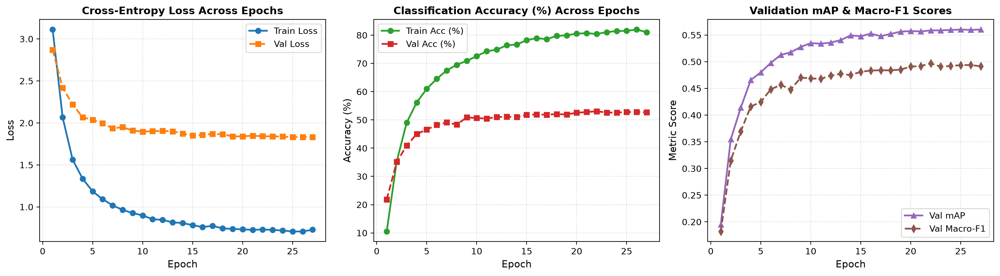

In [ ]:
import matplotlib.pyplot as plt

# 1. Plot Training & Validation Curves
_epochs = [h["epoch"] for h in training_history] if training_history else [1]
_fig, _axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=100)

# Panel 1: Loss
_axes[0].plot(_epochs, [h["train_loss"] for h in training_history], "o-", label="Train Loss", color="#1f77b4", linewidth=2)
_axes[0].plot(_epochs, [h["val_loss"] for h in training_history], "s--", label="Val Loss", color="#ff7f0e", linewidth=2)
_axes[0].set_title("Cross-Entropy Loss Across Epochs", fontsize=12, fontweight="bold")
_axes[0].set_xlabel("Epoch", fontsize=11)
_axes[0].set_ylabel("Loss", fontsize=11)
_axes[0].legend(frameon=True)
_axes[0].grid(True, linestyle=":", alpha=0.6)

# Panel 2: Accuracy
_axes[1].plot(_epochs, [h["train_acc"] * 100.0 for h in training_history], "o-", label="Train Acc (%)", color="#2ca02c", linewidth=2)
_axes[1].plot(_epochs, [h["val_acc"] * 100.0 for h in training_history], "s--", label="Val Acc (%)", color="#d62728", linewidth=2)
_axes[1].set_title("Classification Accuracy (%) Across Epochs", fontsize=12, fontweight="bold")
_axes[1].set_xlabel("Epoch", fontsize=11)
_axes[1].set_ylabel("Accuracy (%)", fontsize=11)
_axes[1].legend(frameon=True)
_axes[1].grid(True, linestyle=":", alpha=0.6)

# Panel 3: mAP & Macro-F1
_axes[2].plot(_epochs, [h["val_mAP"] for h in training_history], "^-", label="Val mAP", color="#9467bd", linewidth=2)
_axes[2].plot(_epochs, [h["val_macro_f1"] for h in training_history], "d--", label="Val Macro-F1", color="#8c564b", linewidth=2)
_axes[2].set_title("Validation mAP & Macro-F1 Scores", fontsize=12, fontweight="bold")
_axes[2].set_xlabel("Epoch", fontsize=11)
_axes[2].set_ylabel("Metric Score", fontsize=11)
_axes[2].legend(frameon=True)
_axes[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()

# 2. Print Evaluation Summary Table (ALL and Per-SNR)
_all_n = len(val_dataset)
_all_acc = final_eval_metrics.get("acc", 0.0) * 100.0
_all_prec = final_eval_metrics.get("precision", 0.0)
_all_rec = final_eval_metrics.get("recall", 0.0)
_all_macro_f1 = final_eval_metrics.get("macro_f1", 0.0)
_all_micro_f1 = final_eval_metrics.get("micro_f1", 0.0)
_all_map = final_eval_metrics.get("mAP", 0.0)

print("\n" + "=" * 95)
print("                 DUAL-CED-TINY OVERALL & PER-SNR EVALUATION SUMMARY")
print("=" * 95)
print(f"{'SNR Level':<12} | {'Count (N)':<10} | {'Accuracy (%)':<14} | {'Precision':<10} | {'Recall':<10} | {'Macro-F1':<10} | {'mAP':<10}")
print("-" * 95)
print(f"{'ALL':<12} | {_all_n:<10d} | {_all_acc:>11.2f}%  | {_all_prec:>10.4f} | {_all_rec:>10.4f} | {_all_macro_f1:>10.4f} | {_all_map:>10.4f}")
print("-" * 95)

for _snr_val in SNR_LEVELS:
    _key = f"{int(_snr_val)}dB"
    _st = final_snr_breakdown.get(_key, {"n": 0, "acc": 0.0, "precision": 0.0, "recall": 0.0, "macro_f1": 0.0, "micro_f1": 0.0, "mAP": 0.0})
    _n = _st.get("n", 0)
    _acc = _st.get("acc", 0.0) * 100.0
    _prec = _st.get("precision", 0.0)
    _rec = _st.get("recall", 0.0)
    _f1 = _st.get("macro_f1", 0.0)
    _map = _st.get("mAP", 0.0)
    print(f"{_key:<12} | {_n:<10d} | {_acc:>11.2f}%  | {_prec:>10.4f} | {_rec:>10.4f} | {_f1:>10.4f} | {_map:>10.4f}")

print("=" * 95)
print(f"Best Validation Accuracy achieved: {best_val_acc * 100.0:.2f}% (Epoch {best_epoch})")
print(f"Model Checkpoint: {RESULTS_ROOT / 'best_model.pt'}")
print("=" * 95 + "\n")

_fig

In [ ]:
# Final evaluation: multi-crop overlap inference on the validation split (best checkpoint).
# 3 crops x 3.2 s at starts 0.0 / 0.4 / 0.8 s, average logits (replaces the old 3-way TTA).
import json as _json
from tqdm.auto import tqdm as _tqdm

_overlap_ckpt_path = RESULTS_ROOT / "best_model.pt"
_overlap_ckpt = torch.load(_overlap_ckpt_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(_overlap_ckpt["model_state_dict"])
model.eval()

_overlap_crop_samples = min(int(round(OVERLAP_CROP_SECONDS * SAMPLE_RATE)), NUM_SAMPLES)
_overlap_max_start = NUM_SAMPLES - _overlap_crop_samples
if OVERLAP_NUM_WINDOWS <= 1 or _overlap_max_start <= 0:
    _overlap_starts = [0]
else:
    _overlap_starts = sorted({
        int(round(_i * _overlap_max_start / (OVERLAP_NUM_WINDOWS - 1)))
        for _i in range(OVERLAP_NUM_WINDOWS)
    })


@torch.no_grad()
def _overlap_logits(_wave, _router_snr):
    _preds = []
    for _start in _overlap_starts:
        _chunk = _wave[..., _start:_start + _overlap_crop_samples]
        _spec = model.frontend(_chunk)
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
            _z_low = model.low_expert(_spec)
            _z_high = model.high_expert(_spec)
        _z_low, _z_high = _z_low.float(), _z_high.float()
        _alpha = (_router_snr >= ROUTER_THRESHOLD_DB).float().unsqueeze(-1)
        _preds.append((1.0 - _alpha) * _z_low + _alpha * _z_high)
    _stacked = torch.stack(_preds, dim=0)
    if OVERLAP_AGGREGATE == "probs":
        return torch.softmax(_stacked, dim=-1).mean(dim=0)
    return _stacked.mean(dim=0)


_all_1pass, _all_overlap, _all_targets, _all_snrs = [], [], [], []
with torch.no_grad():
    for _batch in _tqdm(val_loader, desc="Overlap eval [Val]"):
        _wave = _batch["waveform"].to(DEVICE, non_blocking=True)
        _wave = _wave * (INPUT_RMS / (_wave.pow(2).mean(dim=-1, keepdim=True).sqrt() + 1e-8))
        _y = _batch["target_idx"].to(DEVICE, non_blocking=True)
        _snr = _batch["snr_db"].to(DEVICE, non_blocking=True)
        _router_snr = estimate_router_snr(_wave)

        _spec = model.frontend(_wave)
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16, enabled=USE_BF16):
            _z_low = model.low_expert(_spec)
            _z_high = model.high_expert(_spec)
        _z_low, _z_high = _z_low.float(), _z_high.float()
        _alpha = (_router_snr >= ROUTER_THRESHOLD_DB).float().unsqueeze(-1)
        _fused = (1.0 - _alpha) * _z_low + _alpha * _z_high

        _all_1pass.append(_fused.cpu())
        _all_overlap.append(_overlap_logits(_wave, _router_snr).cpu())
        _all_targets.append(_y.cpu())
        _all_snrs.append(_snr.cpu())

_cat_1pass = torch.cat(_all_1pass)
_cat_overlap = torch.cat(_all_overlap)
_cat_targets = torch.cat(_all_targets)
_cat_snrs = torch.cat(_all_snrs)

_overall_1pass = compute_metrics(_cat_1pass, _cat_targets, num_classes=NUM_CLASSES)
_overall_overlap = compute_metrics(_cat_overlap, _cat_targets, num_classes=NUM_CLASSES)
_breakdown_1pass = compute_snr_breakdown(_cat_1pass, _cat_targets, _cat_snrs, num_classes=NUM_CLASSES)
_breakdown_overlap = compute_snr_breakdown(_cat_overlap, _cat_targets, _cat_snrs, num_classes=NUM_CLASSES)

_best_acc = _overlap_ckpt.get("best_val_acc")
_best_acc_txt = f"{float(_best_acc) * 100:.2f}%" if _best_acc is not None else "n/a"

print("=" * 100)
print("OVERLAP INFERENCE EVALUATION (validation split, best checkpoint; estimated energy router)")
print(f"Checkpoint: {_overlap_ckpt_path} | Epoch: {_overlap_ckpt.get('epoch', 'n/a')} | Val Acc: {_best_acc_txt}")
print(f"Crops: {OVERLAP_NUM_WINDOWS} x {OVERLAP_CROP_SECONDS}s | Starts (s): "
      f"{[round(_s / SAMPLE_RATE, 3) for _s in _overlap_starts]} | Aggregate: {OVERLAP_AGGREGATE}")
print("=" * 100)
print(f"{'Protocol':<12} | {'Acc (%)':>9} | {'Precision':>9} | {'Recall':>9} | {'Macro-F1':>9} | {'Micro-F1':>9} | {'mAP':>9}")
print("-" * 100)
for _name, _m in (("1-pass", _overall_1pass), ("overlap", _overall_overlap)):
    print(f"{_name:<12} | {_m['acc'] * 100:>8.2f}% | {_m['precision']:>9.4f} | {_m['recall']:>9.4f} | "
          f"{_m['macro_f1']:>9.4f} | {_m['micro_f1']:>9.4f} | {_m['mAP']:>9.4f}")
print("-" * 100)
print(f"{'SNR':<6} | {'N':>5} | {'1-pass Acc':>10} | {'Overlap Acc':>11} | {'Delta':>7}")
print("-" * 60)
for _snr_val in SNR_LEVELS:
    _key = f"{int(_snr_val)}dB"
    _st_1p = _breakdown_1pass.get(_key, {"n": 0, "acc": 0.0})
    _st_ov = _breakdown_overlap.get(_key, {"n": 0, "acc": 0.0})
    _delta = (_st_ov["acc"] - _st_1p["acc"]) * 100.0
    print(f"{_key:<6} | {_st_1p['n']:>5d} | {_st_1p['acc'] * 100:>9.2f}% | {_st_ov['acc'] * 100:>10.2f}% | "
          f"{_delta:>+6.2f}%")
print("=" * 100)

overlap_eval_result = {
    "checkpoint": str(_overlap_ckpt_path),
    "checkpoint_epoch": int(_overlap_ckpt.get("epoch", -1)),
    "split": "eval",
    "routing": "estimated_energy_snr_from_residual",
    "num_samples": len(val_dataset),
    "preprocessing": {"normalization": "rms", "input_rms": INPUT_RMS},
    "overlap": {
        "enabled": USE_OVERLAP,
        "num_windows": OVERLAP_NUM_WINDOWS,
        "crop_seconds": OVERLAP_CROP_SECONDS,
        "starts_seconds": [round(_s / SAMPLE_RATE, 4) for _s in _overlap_starts],
        "aggregate": OVERLAP_AGGREGATE,
    },
    "overall": _overall_1pass,
    "snr_breakdown": _breakdown_1pass,
    "overlap_overall": _overall_overlap,
    "overlap_snr_breakdown": _breakdown_overlap,
}
with open(RESULTS_ROOT / "overlap_eval.json", "w", encoding="utf-8") as _f:
    _json.dump(overlap_eval_result, _f, indent=2)
print(f"Saved overlap evaluation to {RESULTS_ROOT / 'overlap_eval.json'}")

Overlap eval [Val]: 100%|██████████| 96/96 [00:04<00:00, 21.93it/s]


OVERLAP INFERENCE EVALUATION (validation split, best checkpoint; estimated energy router)
Checkpoint: /results/dual-ced-tiny/frcrn/best_model.pt | Epoch: 22 | Val Acc: 53.07%
Crops: 3 x 3.2s | Starts (s): [0.0, 0.4, 0.8] | Aggregate: logits
Protocol     |   Acc (%) | Precision |    Recall |  Macro-F1 |  Micro-F1 |       mAP
----------------------------------------------------------------------------------------------------
1-pass       |    53.07% |    0.5152 |    0.5151 |    0.4970 |    0.5307 |    0.5587
overlap      |    50.20% |    0.5081 |    0.4883 |    0.4757 |    0.5020 |    0.5453
----------------------------------------------------------------------------------------------------
SNR    |     N | 1-pass Acc | Overlap Acc |   Delta
------------------------------------------------------------
-5dB   |   536 |     58.02% |      56.16% |  -1.87%
0dB    |   511 |     58.32% |      54.99% |  -3.33%
5dB    |   488 |     54.30% |      51.02% |  -3.28%
10dB   |   513 |     53.22% |    